# NYC Taxi Trip Duration: Exploratory Data Analysis

## Project Overview

The objective of this project is to predict the duration of taxi trips in New York City using the available trip records.

The notebook progresses from an initial inspection of the original data
to feature engineering, a preview of the enriched dataset, and a detailed
exploratory analysis of the original and engineered features. The Deep EDA
section investigates distributions, relationships, temporal patterns,
geographic concentration, categorical features, and potential data-quality
issues.

Model training and feature-selection experiments are handled separately.
The predictive value of the engineered features will be evaluated during
those experiments rather than assumed from the EDA alone.

## Table of Contents

1. Libraries and Configuration
2. Data Loading and Initial Checks
3. Initial Exploration of the Original Features
4. Why Feature Engineering?
5. Feature Engineering
   - Datetime Feature Extraction
   - Haversine Distance
   - Manhattan-Style Distance
   - Pickup Bearing
   - Airport Proximity
   - Rush-Hour Distance Interactions
   - Spatial Grid and Day–Hour Categories
   - Cyclical Time Features
   - Distance Relationship Features
   - Target Log Transformation
   - Log-Scaled Geographic Distances
6. Feature-Engineered Dataset Preview
   - Data Inspection and Quality Checks
   - Column Reference
   - Numerical and Categorical Feature Selection
7. Deep EDA
   - Target and Distance
     1. Trip Duration vs. Geographic Distance
     2. Distance Distributions and Extreme Values
     3. Effect of Log-Scaling on Distance Distributions
   - Temporal Patterns
     1. Trip Duration by Hour, Day, and Month
     2. Weekday vs. Weekend
     3. Rush-Hour Patterns
     4. Cyclical Time Encodings
   - Geographic Patterns
     1. Pickup and Drop-off Location Concentration
     2. Spatial Grid Frequency and Trip Duration
     3. Extreme Distances and Potentially Suspicious Coordinates
   - Airport Proximity and Direction
     1. Trip Duration by Airport Proximity
     2. Pickup Bearing, Distance, and Identical Endpoints
   - Categorical Features and Feature Relationships
     1. Vendor, Store-and-Forward, and Day–Hour Categories
     2. Spatial Category Frequency and Sparsity
     3. Haversine vs. Manhattan-Style Distance
     4. Distance Relationship Features

---

## Libraries and Configuration

The notebook uses pandas for data inspection and custom project modules for data loading, feature engineering, and visualization. Keeping these operations in separate modules allows the same transformations to be reused in the modeling scripts.

In [1]:
import pandas as pd

from taxi_trip_duration.manipulation.data_helper import (
    cat_num_features,
    checking_data,
    load_dataset,
)
from taxi_trip_duration.manipulation.feature_engineering import (
    airport_distances,
    cyclical_time,
    date_time,
    distance_relationships,
    haversine_distance,
    heavy_hitter_categories,
    log_distances,
    manhattan_distance,
    pickup_bearing,
    target_log,
    time_interactions,
)
from taxi_trip_duration.visualization.plotting import (
    plot_airport_proximity_patterns,
    plot_bearing_distance_patterns,
    plot_categorical_duration_patterns,
    plot_cyclical_time_encodings,
    plot_distance_distributions,
    plot_distance_log_scaling,
    plot_distance_metric_comparison,
    plot_distance_relationship_patterns,
    plot_distance_vs_duration,
    plot_extreme_distance_coordinates,
    plot_geographic_distribution,
    plot_pickup_dropoff_density,
    plot_rush_hour_patterns,
    plot_spatial_category_sparsity,
    plot_spatial_grid_patterns,
    plot_target_distribution,
    plot_temporal_patterns,
    plot_weekday_weekend_patterns,
)
from taxi_trip_duration.visualization.summaries import (
    display_distance_duration_summary,
    display_temporal_summary,
    summarize_airport_proximity,
    summarize_bearing_distance_patterns,
    summarize_categorical_duration,
    summarize_cyclical_encodings,
    summarize_distance_distributions,
    summarize_distance_metric_comparison,
    summarize_distance_relationship_patterns,
    summarize_extreme_distance_coordinates,
    summarize_location_coverage,
    summarize_log_distance_distributions,
    summarize_rush_hour_patterns,
    summarize_spatial_category_sparsity,
    summarize_spatial_grid_patterns,
    summarize_temporal_patterns,
    summarize_weekday_weekend,
)

pd.options.display.max_columns = 100

## Data Loading and Initial Checks

The training, validation, and test sets were prepared separately during
the data-splitting stage. This notebook uses only the training split for
descriptive exploration and feature inspection.

The validation split remains available for comparing model configurations,
while the test set is reserved for the final evaluation.

Because repeated experimentation can influence decisions based on validation
results, validation performance should be interpreted as a model-selection
result rather than a completely independent final estimate. The test set
should remain untouched until the final evaluation.

In [2]:
train, _, _ = load_dataset()
df = train.copy()
df.sample(5, random_state=42)

Loading datasets from: dataset/split/


,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
987231,id1829218,2,2016-02-09 12:48:29,1,-73.956863,40.780392,-73.974800,40.750881,N,1194
79954,id0242221,1,2016-06-10 17:46:46,1,-73.977203,40.756180,-73.962379,40.776016,N,538
567130,id3328367,1,2016-04-01 15:12:17,1,-73.987808,40.737904,-73.985321,40.670361,N,2274
500891,id0946645,2,2016-03-03 23:48:58,1,-73.781799,40.644791,-73.919296,40.845482,N,1741
55399,id3347823,2,2016-06-10 20:47:15,1,-73.976570,40.739437,-73.994560,40.697933,N,644


### Dataset Structure

Before applying transformations, it is useful to identify the original columns and the information each one represents.

| Column | Description |
|---|---|
| `id` | Identifier assigned to a trip record. |
| `vendor_id` | Code identifying the trip-record provider. |
| `pickup_datetime` | Timestamp when the meter was engaged. |
| `passenger_count` | Recorded number of passengers. |
| `pickup_longitude` | Longitude of the pickup location. |
| `pickup_latitude` | Latitude of the pickup location. |
| `dropoff_longitude` | Longitude of the drop-off location. |
| `dropoff_latitude` | Latitude of the drop-off location. |
| `store_and_fwd_flag` | Indicates whether the trip record was stored in vehicle memory before being sent to the provider (`Y`) or sent directly (`N`). |
| `trip_duration` | Trip duration in seconds; the prediction target. |

These columns provide identifiers, categorical information, a timestamp, geographic coordinates, and the target variable. The initial checks below establish their data types and help identify possible quality issues before any new features are created.

---

### Initial Data-Quality Checks

The following checks summarize the dataset's completeness, duplicated records, and other basic data-quality characteristics. They provide an initial overview rather than a complete assessment of whether every value is realistic.

In particular, the absence of missing values does not guarantee that coordinates, passenger counts, or trip durations are valid. Those values require separate plausibility checks during the exploration.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 10 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1000000 non-null  str    
 1   vendor_id           1000000 non-null  int64  
 2   pickup_datetime     1000000 non-null  str    
 3   passenger_count     1000000 non-null  int64  
 4   pickup_longitude    1000000 non-null  float64
 5   pickup_latitude     1000000 non-null  float64
 6   dropoff_longitude   1000000 non-null  float64
 7   dropoff_latitude    1000000 non-null  float64
 8   store_and_fwd_flag  1000000 non-null  str    
 9   trip_duration       1000000 non-null  int64  
dtypes: float64(4), int64(3), str(3)
memory usage: 76.3 MB


In [4]:
checking_data(df)

Data Diagnostics:
 - Shape              : (1000000, 10)
 - Missing Values     : 0
 - Duplicate Records  : 0


### Data Diagnostics and Quality Assessment

The initial checks on the training data indicate the following:

- **Dataset size:** 1000000 records and 10 original features.
- **Completeness:** no missing values were found.
- **Duplicate records:** no duplicate rows were found by the check used in this notebook.
- **Data types:** geographic coordinates are stored as `float64`; `passenger_count`, `vendor_id`, and `trip_duration` are stored as `int64`.
- **Timestamp representation:** `pickup_datetime` is currently an object/string column, so it needs parsing before useful calendar and clock components can be extracted.

These checks suggest that explicit missing-value imputation and duplicate-row removal are not required for the inspected data. They do not, by themselves, confirm that all values are plausible: coordinate ranges, unusually short or long trips, and other outliers may still warrant separate investigation.

---

## Initial Exploration of the Original Features

The initial exploration focuses on a few questions that can be answered before creating additional features:

- What does the distribution of `trip_duration` look like?
- Are there coordinates that appear far from the main NYC data cluster?
- Are there extreme observations that need closer investigation?

At this stage, the goal is to identify patterns and questions for further analysis, not to make final decisions about filtering observations.


---

### Target Variable: `trip_duration`

Trip duration is recorded in seconds and is the target the model will predict. Examining its distribution helps us understand the range of trip durations and determine whether a small number of long trips substantially extend the distribution's right tail.

The following visualization provides two complementary views of the target:

- **Raw duration:** the left panel displays trips with durations below 7,200 seconds (two hours). Restricting the displayed observations makes the distribution of shorter trips easier to inspect.
- **Log-transformed duration:** the right panel displays the `log1p` transformation of trip duration across the dataset.

The logarithmic transformation compresses larger values and changes the scale of the target. It is a candidate transformation to evaluate during model development, rather than a requirement for linear models.

Because the two panels use different subsets and scales, they should be interpreted as complementary views rather than a direct comparison of identical distributions.

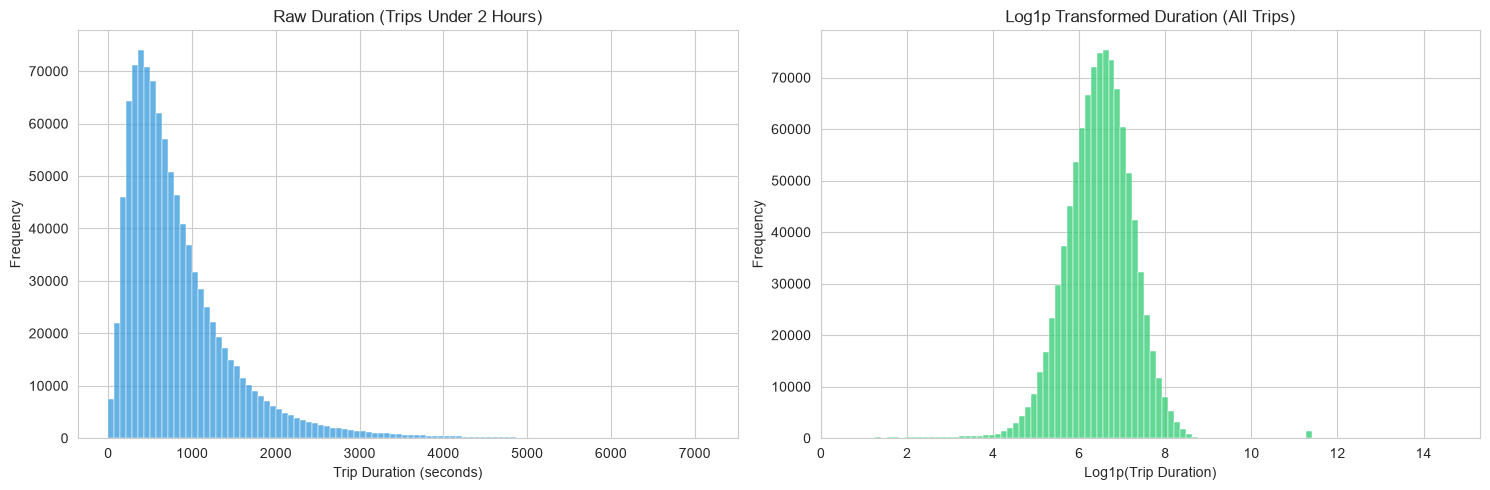

In [5]:
plot_target_distribution(df)

**What to examine**

The left panel helps us inspect the distribution of trips shorter than two hours, while the right panel shows how the logarithmic transformation represents the target across all observations.

Check whether the transformed distribution is more compact and whether a substantial right tail remains. The transformation compresses large durations, but the plot alone cannot establish that unusually long trips are erroneous or that the transformation will improve predictive performance.

The decision to use the transformed target will be evaluated through model-validation experiments.

---

### Geographic Distribution of Pickup Locations

The pickup coordinates describe where each trip begins. Visualizing these coordinates helps us examine their spatial concentration and identify patterns within the New York City area.

The plotting function selects a reproducible random sample of up to 100,000 records and displays pickup locations within a predefined geographic window:

- Longitude: -74.5 to -73.3
- Latitude: 40.4 to 41.2

These axis limits focus the visualization on the selected geographic region. Coordinates outside this window are not visible in the plot, so this visualization cannot establish whether the training split contains GPS anomalies farther outside the displayed area.

The plot also includes pickup locations only; it does not display drop-off locations.

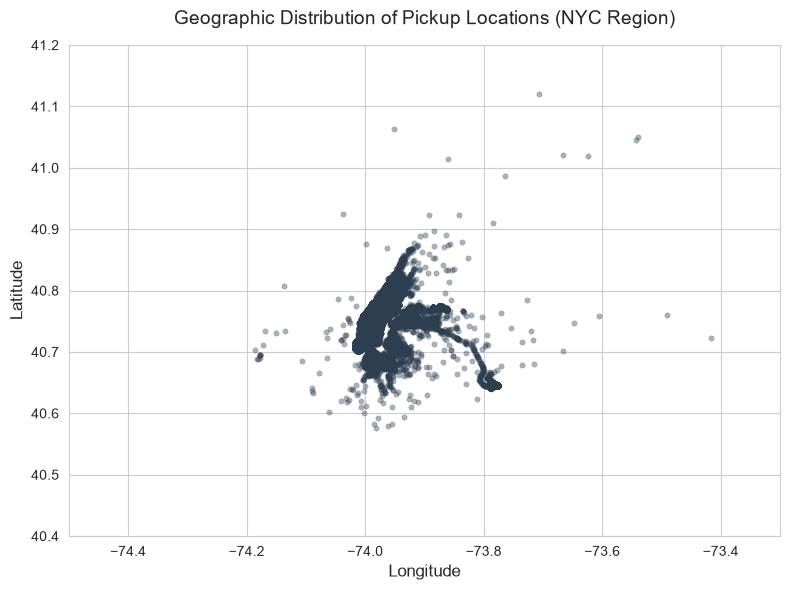

In [6]:
plot_geographic_distribution(df, n_samples=100000)

**What to examine**

Examine the concentration of pickup locations within the displayed region. Look for dense clusters, differences in spatial coverage, and isolated points that may deserve closer investigation.

Because the plot uses a fixed geographic window and a sample of the dataset, its conclusions are limited to the visible observations. Points outside the window cannot be assessed using this figure alone.

To investigate potential GPS errors throughout the dataset, a separate analysis of the full coordinate ranges and potentially invalid locations is needed. Unusual coordinates should be investigated rather than automatically classified as errors.

---

### Preliminary Outlier Strategy

No rows are removed at this stage. The initial plots identify observations that may deserve further investigation, but they are not sufficient on their own to determine which records should be excluded.

Keeping all observations for now avoids making a filtering decision before its impact has been measured. It does **not** mean that every extreme observation is valid or that a model should be expected to learn from GPS errors.

If filtering is considered later, it should be based on explicit, reproducible criteria. The effect of filtering can then be tested as a separate experiment, using a consistent rule across the relevant data splits. The test set must not be used to choose that rule.

---

### What the Initial EDA Suggests

The initial inspection establishes a starting point for feature engineering:

- The distribution of `trip_duration` can help determine whether a transformed target is worth testing.
- The geographic coordinates provide the information needed to derive distance and direction features.
- The timestamp contains temporal information that can be extracted into interpretable calendar and clock components.

These are motivations for further investigation, not proof that any particular engineered feature will improve prediction.

---

## Why Feature Engineering?

The original columns contain useful information, but some relationships are not represented directly.

For example, the four geographic coordinates describe the two endpoints of a trip, but they do not directly provide a single measure of the distance between them. Similarly, a raw timestamp does not explicitly separate recurring patterns by hour or day of the week.

Feature engineering creates additional representations of information already present in the dataset. The transformations below explore several hypotheses:

- **Geographic features:** distance estimates and bearing may summarize the spatial relationship between pickup and drop-off locations.
- **Airport proximity:** endpoint distances to airport reference points may help distinguish trips near major airports.
- **Temporal features:** calendar components and cyclical encodings may represent recurring travel patterns.
- **Interaction features:** combining distance estimates with a rush-hour indicator may allow the model to represent different distance–duration relationships across time periods.
- **Categorical representations:** spatial grids and day–hour groups may capture recurring local patterns.
- **Transformed features:** logarithmic distances and relationships between distance estimates may provide alternative representations for the model to evaluate.

Each transformation is a hypothesis rather than a guaranteed improvement. After generating the features, the deeper EDA will examine their distributions, relationships, and limitations. Model experiments will determine which representations are useful for prediction.

---

## Feature Engineering

This section applies the planned transformations to the dataframe. Each subsection explains the purpose and limitations of the feature before the corresponding function is called.

The transformations are applied sequentially so that the resulting dataframe contains the original columns together with the engineered features. The precise output column names and implementation details are defined in the functions in `feature_engineering.py`.

### Datetime Feature Extraction

The original `pickup_datetime` column represents a timestamp. Extracting its calendar and clock components makes temporal information available as separate features.

The function derives components such as:

- `pickup_hour` — hour of the day, which may represent daily travel patterns.
- `pickup_day_of_week` — day of the week, which may distinguish weekday and weekend patterns.
- `pickup_month` — month of the year, which may capture broad seasonal differences.
- `pickup_day_of_year` — position within the year.

With `eda=True`, the function also retains `pickup_date` and `pickup_time` for exploration and plotting. These fields are useful for analysis, but they should only be included in modeling if their role is intentional and appropriate for the prediction task.

In [7]:
df = date_time(df, eda=True)

### Haversine Distance

Haversine distance estimates the great-circle distance between the pickup and drop-off coordinates on a spherical Earth. It provides a direct geographic-distance measure, rather than an estimate of the actual road route taken by a taxi.

The coordinates are expressed in radians in the following equations. Let $\phi_1$ and $\phi_2$ represent the pickup and drop-off latitudes, and let $\lambda_1$ and $\lambda_2$ represent their longitudes.

First, calculate:

$$
a =
\sin^2\left(\frac{\phi_2-\phi_1}{2}\right)
+
\cos(\phi_1)\cos(\phi_2)
\sin^2\left(\frac{\lambda_2-\lambda_1}{2}\right)
$$

Then:

$$
c = 2\arcsin\left(\sqrt{a}\right)
$$

Finally, using an Earth radius of approximately $6371.0$ km:

$$
d_{\text{Haversine}} = 6371.0c
$$

The resulting distance is an estimate of the shortest surface distance between the two endpoints. The actual taxi route may be longer because of the street network, traffic restrictions, bridges, and other factors.

In [8]:
df = haversine_distance(df)

### Manhattan-Style Distance

Manhattan-style distance provides an approximate distance based on separate north–south and east–west components. It is inspired by grid-like travel, but it is not an exact road-network distance and does not account for the actual streets or route restrictions.

Let $R$ be the Earth's radius, $\phi_1$ and $\phi_2$ be the endpoint latitudes, and $\lambda_1$ and $\lambda_2$ be their longitudes. The angular coordinates in these equations are in radians.

The north–south component is:

$$
d_{NS} = R \left|\phi_2-\phi_1\right|
$$

The mean latitude is:

$$
\phi_{\text{mean}} = \frac{\phi_1+\phi_2}{2}
$$

The east–west component is approximated at the mean latitude:

$$
d_{EW} =
R\cos(\phi_{\text{mean}})
\left|\lambda_2-\lambda_1\right|
$$

The combined Manhattan-style distance is:

$$
d_{\text{Manhattan}} = d_{NS}+d_{EW}
$$

This feature provides a different estimate of endpoint separation from Haversine distance. Whether that difference is useful for predicting trip duration will be investigated later.

In [9]:
df = manhattan_distance(df)

### Pickup Bearing

Pickup bearing represents the initial compass direction from the pickup coordinates toward the drop-off coordinates. It summarizes the geographic orientation of the trip endpoints.

It should not be interpreted as the taxi's actual road direction: the route may turn, follow a road network, or be constrained by one-way streets.

Let $\phi_1$ and $\phi_2$ represent the pickup and drop-off latitudes, and let $\Delta\lambda$ represent the difference in longitude. The angular coordinates are expressed in radians.

The intermediate values are calculated as follows:

$$
\begin{aligned}
Y &= \sin(\Delta\lambda)\cos(\phi_2)\\[8pt]
X &= \cos(\phi_1)\sin(\phi_2) - \sin(\phi_1)\cos(\phi_2)\cos(\Delta\lambda)
\end{aligned}
$$

The initial bearing in degrees is:

$$
\theta = \operatorname{atan2}(Y,X)\frac{180}{\pi}
$$

The resulting bearing is typically represented in the range $-180^\circ$ to $180^\circ$.

In [10]:
df = pickup_bearing(df)

### Airport Proximity

Trips beginning or ending near major airports may differ from other journeys in their route characteristics and travel conditions. Endpoint distances to airport reference coordinates provide one way to represent this proximity.

The reference coordinates used by this project are:

- **John F. Kennedy International Airport (JFK):** latitude `40.6413`, longitude `-73.7781`
- **LaGuardia Airport (LGA):** latitude `40.7769`, longitude `-73.8740`
- **Newark Liberty International Airport (EWR):** latitude `40.6895`, longitude `-74.1745`

These measurements indicate geographic proximity to the selected reference points. They do not establish that a trip actually starts or ends at an airport, nor do they measure distance to a particular terminal entrance or road.

The exact output column names are defined by `airport_distances()`.

In [11]:
df = airport_distances(df)

### Rush-Hour Distance Interactions

The relationship between geographic distance and trip duration may vary by time of day. For example, the duration of a given distance may differ between a busy period and a quieter period.

An interaction between a distance feature and a binary rush-hour indicator allows the model to represent a different contribution from that distance during the selected period.

This transformation creates `is_rush_hour` and interactions with the Haversine and Manhattan-style distance estimates. With a binary indicator, each interaction is zero outside the defined rush-hour period and equals its corresponding distance inside that period.

The exact hours and weekday conditions are determined by `time_interactions()`. The implementation should define these conditions explicitly so that the feature is reproducible and easy to interpret.

In [12]:
df = time_interactions(df)

### Spatial Grid and Day–Hour Categories

Geographic coordinates and timestamps can also be represented as categorical groups. These features may help capture repeated patterns associated with specific locations or time slots.

**Spatial grids**

Rounding latitude and longitude to a chosen precision groups nearby endpoints into approximate geographic cells. At a precision of two decimal places, nearby coordinates may share a category. However, the physical dimensions of these cells vary with latitude, so they should not be treated as uniform one-kilometre squares.

**Day–hour category**

Combining the day of the week with the pickup hour creates a category representing a recurring weekly time slot, such as a particular hour on a particular day.

These categories may capture local patterns that continuous features do not represent as directly. However, categories with many distinct values can create a high-dimensional representation after encoding. Their usefulness and risk of overfitting must be evaluated empirically.

The exact category names and precision are defined by `heavy_hitter_categories()`.

In [13]:
df = heavy_hitter_categories(df)

### Cyclical Time Features

Time variables are periodic. For example, hour 23 is adjacent to hour 0, although their raw numerical values are far apart. The same issue occurs at the boundary between the last and first days of a week.

Sine and cosine transformations represent this periodic structure by mapping the values onto a circle.

For pickup hour $h$, the transformations are:

$$
\begin{aligned}
\text{pickup\_hour\_sin} &= \sin\left(\frac{2\pi h}{24}\right)\\
\text{pickup\_hour\_cos} &= \cos\left(\frac{2\pi h}{24}\right)
\end{aligned}
$$

For day of the week $d$, where Monday is represented by $0$ and Sunday by $6$:

$$
\begin{aligned}
\text{pickup\_day\_sin} &= \sin\left(\frac{2\pi d}{7}\right)\\
\text{pickup\_day\_cos} &= \cos\left(\frac{2\pi d}{7}\right)
\end{aligned}
$$

These encodings preserve the cyclical relationship between the beginning and end of each period. They supplement the original time components; the validation experiments will determine whether they add useful predictive information.

In [14]:
df = cyclical_time(df)

### Distance Relationship Features

Haversine and Manhattan-style distances are different estimates of the geographic separation between pickup and drop-off locations. Their relationship may itself contain useful information.

Two possible representations are the ratio between the estimates and their difference.

The distance ratio is:

$$
\begin{aligned}
\text{distance\_ratio}
&= \frac{d_{\text{Manhattan}}}
{d_{\text{Haversine}}+\epsilon}\\[8pt]
\text{distance\_difference}
&= d_{\text{Manhattan}}-d_{\text{Haversine}}
\end{aligned}
$$

Here, $\epsilon=10^{-6}$ is added to the denominator to prevent division by zero.

These features describe the relationship between the two distance estimates; they do not directly measure the true road-route distance. The exact output column names are determined by `distance_relationships()`.

In [15]:
df = distance_relationships(df)

### Target Log Transformation

The initial target plot can indicate whether trip duration has a long right tail. A logarithmic transformation compresses larger durations and changes the target scale used during model training.

The transformation is:

$$
y_{\text{log}} = \ln(y+1)
$$

where $y$ is the original trip duration in seconds. Adding one allows the transformation to be calculated for a duration of zero.

The transformed target is stored in `log1p_trip_duration`. Here, `drop_original=False` retains `trip_duration` so that the original values remain available for EDA.

During model training, the target must be separated from the predictors. Neither `trip_duration` nor `log1p_trip_duration` should be included among the input features when predicting trip duration.

In [16]:
df = target_log(df, drop_original=False)

### Log-Scaled Geographic Distances

Geographic distances may also have right-skewed distributions. Applying `log1p` compresses larger values and provides an alternative scale for representing distance.

For distances measured in kilometres, the transformations are:

$$
\begin{aligned}
\text{log\_haversine}
&= \ln\left(1+d_{\text{Haversine}}\right)\\[8pt]
\text{log\_manhattan}
&= \ln\left(1+d_{\text{Manhattan}}\right)
\end{aligned}
$$

Adding one keeps the transformation defined when the distance is zero. The transformed columns supplement the original distance estimates rather than replacing them.

Whether these transformations improve the model depends on the relationship between distance and the target, as well as the estimator being used. Their contribution will be assessed through controlled validation experiments.

In [17]:
df = log_distances(df)

---

## Feature-Engineered Dataset Preview

After applying the feature-engineering transformations, we inspect the resulting
dataframe to understand its structure and verify that the expected columns
have been generated.

This section serves as a preliminary checkpoint before the deeper visual
analysis. It allows us to review the enriched dataset, check its data types
and data quality, and identify which features are selected for the current
best model configuration.

The next stage will use targeted visualizations to investigate the
distributions and relationships of the original and engineered features.

In [18]:
df.sample(5, random_state=42)

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,pickup_hour,pickup_day_of_week,pickup_month,pickup_day_of_year,pickup_date,pickup_time,haversine_distance,manhattan_distance,pickup_bearing,pickup_jfk_distance,pickup_lga_distance,pickup_ewr_distance,dropoff_jfk_distance,dropoff_lga_distance,dropoff_ewr_distance,is_rush_hour,rush_hour_manhattan,rush_hour_haversine,pickup_grid,dropoff_grid,day_hour,pickup_dropoff_grid,pickup_hour_sin,pickup_hour_cos,pickup_day_sin,pickup_day_cos,is_weekend,is_night,is_morning_peak,is_evening_peak,distance_ratio,distance_difference,log1p_trip_duration,log_haversine,log_manhattan
987231,id1829218,2,2016-02-09 12:48:29,1,-73.956863,40.780392,-73.974800,40.750881,N,1194,12,1,2,40,2016-02-09,12:48:29,3.612419,4.792004,-155.275377,21.592429,6.987982,20.938027,20.578247,8.968815,18.161062,0,0.000000,0.000000,40.78_-73.96,40.75_-73.97,1_12,40.78_-73.96_to_40.75_-73.97,1.224647e-16,-1.000000,0.781831,0.623490,0,0,0,0,1.326536,1.179584,7.085901,1.528752,1.756478
79954,id0242221,1,2016-06-10 17:46:46,1,-73.977203,40.756180,-73.962379,40.776016,N,538,17,4,6,162,2016-06-10,17:46:46,2.534506,3.454135,29.504894,21.092838,8.991611,18.204827,21.579220,7.442539,20.297669,1,3.454135,2.534506,40.76_-73.98,40.78_-73.96,4_17,40.76_-73.98_to_40.78_-73.96,-9.659258e-01,-0.258819,-0.433884,-0.900969,0,0,0,1,1.362843,0.919629,6.289716,1.262574,1.493833
567130,id3328367,1,2016-04-01 15:12:17,1,-73.987808,40.737904,-73.985321,40.670361,N,2274,15,4,4,92,2016-04-01,15:12:17,7.513368,7.720100,178.400160,20.688528,10.520977,16.630056,17.776615,15.111193,16.094051,0,0.000000,0.000000,40.74_-73.99,40.67_-73.99,4_15,40.74_-73.99_to_40.67_-73.99,-7.071068e-01,-0.707107,-0.433884,-0.900969,0,0,0,0,1.027515,0.206732,7.729735,2.141638,2.165631
500891,id0946645,2,2016-03-03 23:48:58,1,-73.781799,40.644791,-73.919296,40.845482,N,1741,23,3,3,63,2016-03-03,23:48:58,25.142946,33.899076,-27.387106,0.498071,16.618848,33.492258,25.631348,8.525697,27.617648,0,0.000000,0.000000,40.64_-73.78,40.85_-73.92,3_23,40.64_-73.78_to_40.85_-73.92,-2.588190e-01,0.965926,0.433884,-0.900969,0,1,0,0,1.348254,8.756130,7.462789,3.263579,3.552460
55399,id3347823,2,2016-06-10 20:47:15,1,-73.976570,40.739437,-73.994560,40.697933,N,644,20,4,6,162,2016-06-10,20:47:15,4.857691,6.131177,-161.807456,19.977286,9.591053,17.581866,19.311657,13.426750,15.199428,0,0.000000,0.000000,40.74_-73.98,40.7_-73.99,4_20,40.74_-73.98_to_40.7_-73.99,-8.660254e-01,0.500000,-0.433884,-0.900969,0,0,0,0,1.262158,1.273486,6.469250,1.767756,1.964476


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 45 columns):
 #   Column                Non-Null Count    Dtype         
---  ------                --------------    -----         
 0   id                    1000000 non-null  str           
 1   vendor_id             1000000 non-null  int64         
 2   pickup_datetime       1000000 non-null  datetime64[us]
 3   passenger_count       1000000 non-null  int64         
 4   pickup_longitude      1000000 non-null  float64       
 5   pickup_latitude       1000000 non-null  float64       
 6   dropoff_longitude     1000000 non-null  float64       
 7   dropoff_latitude      1000000 non-null  float64       
 8   store_and_fwd_flag    1000000 non-null  str           
 9   trip_duration         1000000 non-null  int64         
 10  pickup_hour           1000000 non-null  int32         
 11  pickup_day_of_week    1000000 non-null  int32         
 12  pickup_month          1000000 non-null  int32         

### Column Reference

After applying the feature-engineering transformations, the dataset contains
45 columns, including the original trip attributes, engineered geographic
and temporal features, categorical representations, and transformed variables.

The table below summarizes each column, its current data type, and its
purpose in the dataset.

#### Original Features

| Feature | Data Type | Description |
|---|---|---|
| `id` | `str` | Identifier assigned to each trip record. |
| `vendor_id` | `int64` | Code identifying the trip-record provider. |
| `pickup_datetime` | `datetime64[us]` | Timestamp when the taxi meter was engaged. |
| `passenger_count` | `int64` | Recorded number of passengers. |
| `pickup_longitude` | `float64` | Longitude of the pickup location. |
| `pickup_latitude` | `float64` | Latitude of the pickup location. |
| `dropoff_longitude` | `float64` | Longitude of the drop-off location. |
| `dropoff_latitude` | `float64` | Latitude of the drop-off location. |
| `store_and_fwd_flag` | `str` | Indicates whether the trip record was stored in vehicle memory before being sent to the provider (`Y`) or sent directly (`N`). |
| `trip_duration` | `int64` | Original trip duration in seconds; the prediction target. |

#### Datetime Features

| Feature | Data Type | Description |
|---|---|---|
| `pickup_hour` | `int32` | Hour of the day when the trip started, ranging from 0 to 23. |
| `pickup_day_of_week` | `int32` | Day of the week when the trip started. The exact numeric mapping depends on the implementation. |
| `pickup_month` | `int32` | Month in which the trip started. |
| `pickup_day_of_year` | `int32` | Day's position within the calendar year. |
| `pickup_date` | `object` | Date extracted from the pickup timestamp for exploration. |
| `pickup_time` | `object` | Time extracted from the pickup timestamp for exploration. |

#### Geographic Distance and Direction Features

| Feature | Data Type | Description |
|---|---|---|
| `haversine_distance` | `float64` | Great-circle distance between pickup and drop-off coordinates, measured in kilometres when using the project's 6371 km Earth radius. |
| `manhattan_distance` | `float64` | Approximate distance based on north–south and east–west geographic components. It is not an exact road-route distance. |
| `pickup_bearing` | `float64` | Initial geographic bearing from the pickup location toward the drop-off location, typically expressed in degrees. |
| `pickup_jfk_distance` | `float64` | Geographic distance from the pickup location to the JFK reference coordinates. |
| `pickup_lga_distance` | `float64` | Geographic distance from the pickup location to the LaGuardia reference coordinates. |
| `pickup_ewr_distance` | `float64` | Geographic distance from the pickup location to the Newark Liberty reference coordinates. |
| `dropoff_jfk_distance` | `float64` | Geographic distance from the drop-off location to the JFK reference coordinates. |
| `dropoff_lga_distance` | `float64` | Geographic distance from the drop-off location to the LaGuardia reference coordinates. |
| `dropoff_ewr_distance` | `float64` | Geographic distance from the drop-off location to the Newark Liberty reference coordinates. |

#### Rush-Hour Features

| Feature | Data Type | Description |
|---|---|---|
| `is_rush_hour` | `int64` | Binary indicator identifying whether the pickup time satisfies the rush-hour conditions defined in the feature-engineering function. |
| `rush_hour_manhattan` | `float64` | Interaction between the Manhattan-style distance and the rush-hour indicator. |
| `rush_hour_haversine` | `float64` | Interaction between Haversine distance and the rush-hour indicator. |

#### Spatial and Time-Slot Categories

| Feature | Data Type | Description |
|---|---|---|
| `pickup_grid` | `str` | Categorical representation of the pickup coordinates using the configured spatial-grid precision. |
| `dropoff_grid` | `str` | Categorical representation of the drop-off coordinates using the configured spatial-grid precision. |
| `day_hour` | `str` | Category combining the pickup day of the week and pickup hour. |
| `pickup_dropoff_grid` | `str` | Combined categorical representation of the pickup and drop-off grid locations. |

#### Cyclical Time Features and Binary Indicators

| Feature | Data Type | Description |
|---|---|---|
| `pickup_hour_sin` | `float64` | Sine encoding of the pickup hour to represent its daily cyclical pattern. |
| `pickup_hour_cos` | `float64` | Cosine encoding of the pickup hour to represent its daily cyclical pattern. |
| `pickup_day_sin` | `float64` | Sine encoding of the pickup day of the week. |
| `pickup_day_cos` | `float64` | Cosine encoding of the pickup day of the week. |
| `is_weekend` | `int64` | Binary indicator identifying weekend trips according to the implementation's weekday mapping. |
| `is_night` | `int64` | Binary indicator identifying trips that fall within the configured nighttime period. |
| `is_morning_peak` | `int64` | Binary indicator identifying trips within the configured morning peak period. |
| `is_evening_peak` | `int64` | Binary indicator identifying trips within the configured evening peak period. |

#### Distance Relationship and Transformation Features

| Feature | Data Type | Description |
|---|---|---|
| `distance_ratio` | `float64` | Ratio of Manhattan-style distance to Haversine distance, with a small constant added to the denominator to avoid division by zero. |
| `distance_difference` | `float64` | Difference between Manhattan-style distance and Haversine distance. |
| `log1p_trip_duration` | `float64` | Log-transformed target calculated as \(\ln(1+\text{trip\_duration})\). |
| `log_haversine` | `float64` | Log-transformed Haversine distance calculated using \(\ln(1+d)\). |
| `log_manhattan` | `float64` | Log-transformed Manhattan-style distance calculated using \(\ln(1+d)\). |

#### Interpretation

The feature-engineered dataset combines the original trip information with
additional representations of geographic distance, direction, time, and
location categories.

These columns do not all serve the same role during model training.
The selected predictor features are determined by the feature configuration
and preprocessing functions. The original identifiers and exploratory
date/time columns are not automatically included as model inputs.

The original `trip_duration` and its transformed version,
`log1p_trip_duration`, represent the same target on different scales.
During model training, `log1p_trip_duration` is used as the target, and
neither target column should be included among the predictors.

The next stage will investigate the distributions and relationships of
these features through targeted visualizations, helping identify patterns,
limitations, and potential directions for further analysis.

In [20]:
checking_data(df)

Data Diagnostics:
 - Shape              : (1000000, 45)
 - Missing Values     : 0
 - Duplicate Records  : 0


### Numerical and Categorical Feature Selection

The dataframe contains columns with different data types, but their pandas
data types do not necessarily determine how they are treated during model
preprocessing.

For the current best feature configuration, `cat_num_features()` identifies
which columns are treated as categorical and which are treated as numerical.

Categorical features are passed through One-Hot Encoding, while numerical
features are passed through the configured numerical preprocessing pipeline.

Binary indicators such as `is_weekend`, `is_night`, `is_morning_peak`,
`is_evening_peak`, and `is_rush_hour` are treated as numerical features
in the current configuration.

The lists below show the selected features for the configuration that
includes the distance relationship features and uses the default spatial
grid precision of 2. They describe the model's feature selection, not
simply the pandas data types of the columns.

In [21]:
categorical_features, numerical_features = cat_num_features(
    haversine_distance=True,
    manhattan_distance=True,
    pickup_bearing=True,
    airport=True,
    interactions=True,
    heavy_hitters=True,
    log_dist=True,
    cyclical_time_features=True,
    distance_relationship_features=True,
)

print(f"Categorical features ({len(categorical_features)}):")

for feature in categorical_features:
    print(f"  - {feature}")

print(f"\nNumerical features ({len(numerical_features)}):")

for feature in numerical_features:
    print(f"  - {feature}")

Categorical features (10):
  - pickup_hour
  - pickup_day_of_week
  - pickup_month
  - pickup_day_of_year
  - passenger_count
  - store_and_fwd_flag
  - pickup_grid
  - dropoff_grid
  - day_hour
  - pickup_dropoff_grid

Numerical features (28):
  - pickup_latitude
  - pickup_longitude
  - dropoff_latitude
  - dropoff_longitude
  - haversine_distance
  - manhattan_distance
  - pickup_bearing
  - pickup_jfk_distance
  - pickup_lga_distance
  - pickup_ewr_distance
  - dropoff_jfk_distance
  - dropoff_lga_distance
  - dropoff_ewr_distance
  - is_rush_hour
  - rush_hour_manhattan
  - rush_hour_haversine
  - log_haversine
  - log_manhattan
  - pickup_hour_sin
  - pickup_hour_cos
  - pickup_day_sin
  - pickup_day_cos
  - is_weekend
  - is_night
  - is_morning_peak
  - is_evening_peak
  - distance_ratio
  - distance_difference


## Deep EDA

The initial EDA established the dataset's structure and identified patterns worth investigating. After creating the engineered features, the next step is to examine their distributions and relationships with trip duration in more detail.

This section focuses on questions that can guide feature selection and identify possible data-quality issues.

**Target and distance**

- How does trip duration vary with Haversine and Manhattan-style distance?
- Do the distance distributions contain extreme values or unusual concentrations?
- Does log-scaling change how the distance distributions are represented?

**Temporal patterns**

- How does trip duration vary by pickup hour, day of the week, and month?
- Do the patterns differ between weekdays and weekends?
- How does the selected rush-hour definition relate to trip duration?
- Do cyclical encodings preserve the intended periodic relationships?

**Geographic patterns**

- Are pickup and drop-off locations concentrated in particular areas?
- Do spatial grid categories differ in their frequency and observed trip-duration distributions?
- Are any extreme distances associated with suspicious coordinates?

**Airport proximity and direction**

- Does trip duration vary with proximity to the selected airport reference points?
- How are bearing and distance distributed, and are there degenerate cases such as identical pickup and drop-off coordinates?

**Categorical features and feature relationships**

- How do `vendor_id`, `store_and_fwd_flag`, and the engineered day–hour categories relate to trip duration?
- Are the spatial categories too sparse to interpret reliably?
- Do Manhattan-style and Haversine distances contain similar information?
- Do the distance relationship features reveal patterns not visible in the individual distance features?

When examining categories, include their observation counts alongside duration summaries so that patterns based on very few trips are not mistaken for general trends. For plots involving many records, use an appropriate sample for visualization while retaining full-data summaries where practical.

The purpose of this section is to describe patterns, investigate hypotheses, and identify limitations. A visual relationship does not establish causation, and a feature that looks informative is not necessarily useful to the model. Predictive value will be determined through controlled experiments using the validation split.

---
### Target and Distance

#### 1. Trip Duration vs. Geographic Distance

Trip duration may be related to the distance between pickup and drop-off locations. This analysis examines the relationship between `trip_duration` and two geographic distance estimates: Haversine distance and Manhattan-style distance.

Both distance features are examined to determine whether they show similar patterns in relation to trip duration. Since the target and distance features can have strongly right-skewed distributions, the analysis uses `log1p` transformations to make the relationships easier to visualize.

A hexbin plot is used because the dataset contains one million observations. It summarizes the concentration of observations in two-dimensional regions without plotting every record individually.

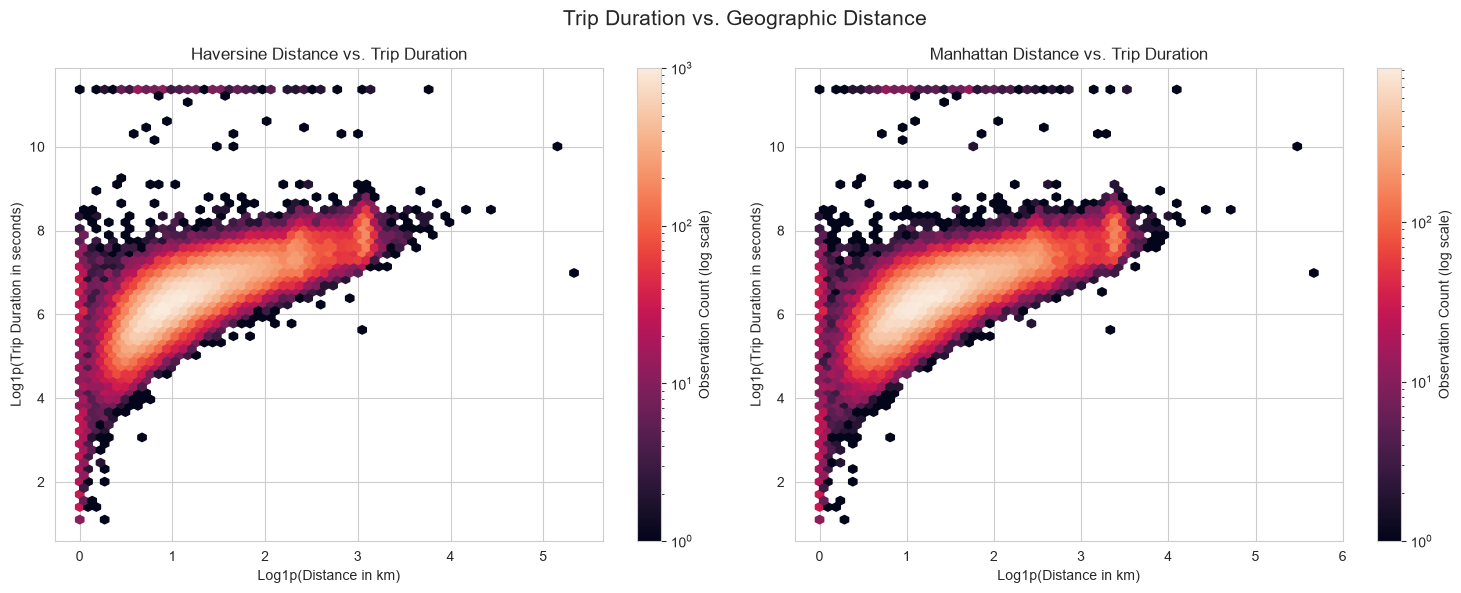

In [22]:
plot_distance_vs_duration(df)

In [23]:
display_distance_duration_summary(df)


Haversine Distance


,distance_bin,trip_count,median_duration_minutes,p90_duration_minutes
0,"(-0.001, 0.792]",100000,3.87,9.25
1,"(0.792, 1.09]",100000,5.48,10.67
2,"(1.09, 1.38]",100000,6.95,12.88
3,"(1.38, 1.704]",100000,8.33,14.95
4,"(1.704, 2.091]",100000,9.80,17.02
5,"(2.091, 2.595]",100000,11.43,19.27
6,"(2.595, 3.331]",100000,13.38,22.15
7,"(3.331, 4.614]",100000,16.07,26.25
8,"(4.614, 7.621]",100000,20.25,32.02
9,"(7.621, 1240.909]",100000,30.85,54.40



Manhattan Distance


,distance_bin,trip_count,median_duration_minutes,p90_duration_minutes
0,"(-0.001, 1.0]",100000,3.98,9.48
1,"(1.0, 1.386]",100000,5.62,10.98
2,"(1.386, 1.762]",100000,7.03,13.20
3,"(1.762, 2.183]",100000,8.35,15.12
4,"(2.183, 2.686]",100000,9.80,17.18
5,"(2.686, 3.343]",100000,11.40,19.43
6,"(3.343, 4.297]",100000,13.30,22.23
7,"(4.297, 5.984]",100000,15.98,26.30
8,"(5.984, 9.668]",100000,20.25,32.43
9,"(9.668, 1328.091]",100000,30.58,54.34


##### Interpretation

Both Haversine and Manhattan-style distance show a clear positive relationship with trip duration. The median duration increases from 3.87 minutes in the lowest Haversine distance bin to 30.85 minutes in the highest bin.

The hexbin plots show a dense, upward-sloping central band, indicating that trips are concentrated around the general relationship between distance and duration. However, substantial variation remains: trips with similar distances can have very different durations, and the 90th-percentile duration is considerably higher than the median across the distance bins.

The distance distributions are strongly right-skewed. In the highest Haversine distance bin, values range from approximately 7.621 km to 1,240.909 km, illustrating how extreme observations extend the upper tail. The plots also reveal trips with zero geographic distance but varying durations, alongside a small number of extremely long trips that warrant further investigation.

Both distance measures display very similar relationships with trip duration, although Manhattan-style distance generally produces higher distance values. These observations suggest that the two features capture related geographic information, but the visualizations and summary statistics alone cannot determine whether including both improves predictive performance.

Overall, geographic distance is informative about trip duration, but it does not fully explain the variation in journey times. The predictive contribution of each distance feature will be evaluated through controlled validation experiments.

---

#### 2. Distance Distributions and Extreme Values

The previous analysis examined how trip duration relates to Haversine and Manhattan-style distance. This section examines the distributions of the two distance features themselves.

Histograms are used to investigate where observations are concentrated and whether the distributions are strongly right-skewed. Summary statistics, including the median, 95th percentile, 99th percentile, and maximum, help quantify the spread and identify potentially extreme values.

The histograms focus on the central 99% of observations to make the main distributions easier to inspect. The summary statistics are calculated using all valid observations, including the upper tail.

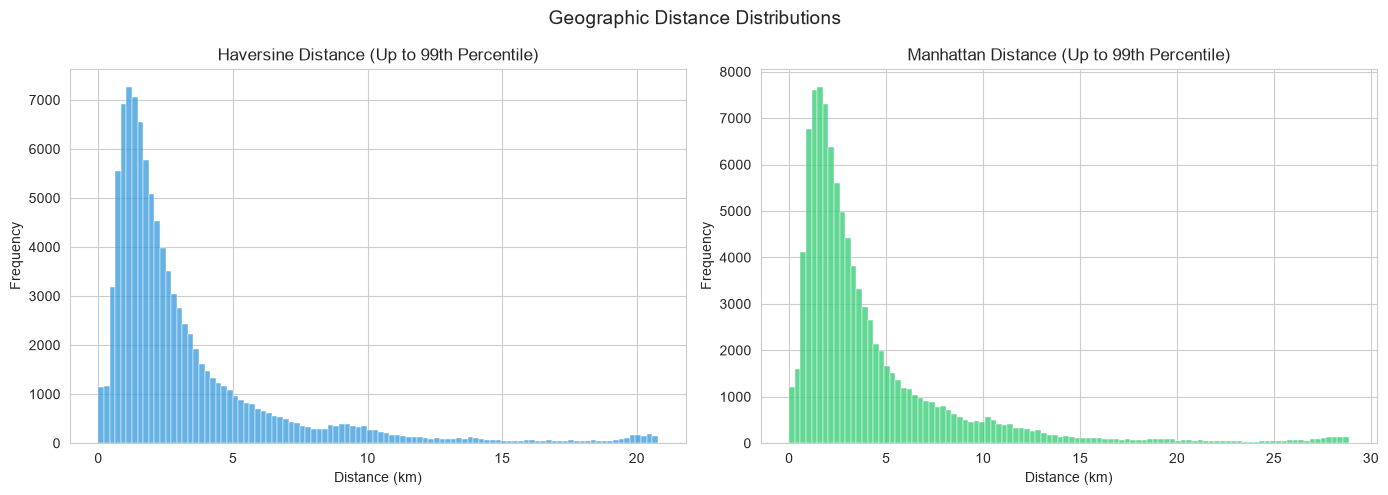

In [24]:
plot_distance_distributions(df)

In [25]:
display(summarize_distance_distributions(df).round(3))

,valid_count,zero_count,median_km,p95_km,p99_km,max_km,above_p99_count
distance_feature,,,,,,,
haversine_distance,1000000,4085,2.091,11.011,20.785,1240.909,10000
manhattan_distance,1000000,4085,2.686,13.947,28.859,1328.091,10000


##### Interpretation

Both Haversine and Manhattan-style distance distributions are strongly right-skewed, with most trips concentrated at shorter distances. The median distance is 2.091 km for Haversine and 2.686 km for Manhattan-style distance.

The 95th percentile reaches 11.011 km for Haversine and 13.947 km for Manhattan-style distance. At the 99th percentile, these values increase to 20.785 km and 28.859 km, respectively, showing that most trips cover relatively short distances while a smaller proportion extend much farther.

The summary statistics identify 4,085 zero-distance trips among the one million training observations. These records have no geographic separation between the pickup and drop-off coordinates according to the distance calculations. Their presence warrants further investigation, but the available statistics do not establish why these trips have zero distance.

The maximum distances are substantially larger than the 99th-percentile values, reaching 1,240.909 km for Haversine and 1,328.091 km for Manhattan-style distance. The summary reports 10,000 observations above the 99th percentile for each measure. These extreme values may represent anomalous records and should be investigated before deciding whether any observations should be filtered.

Both metrics exhibit similar distribution shapes, although Manhattan-style distance consistently produces higher values across the reported statistics. Overall, the distributions confirm a concentration of short trips alongside a long upper tail. The impact of extreme and zero-distance observations should be evaluated carefully rather than assuming that all such records are invalid.

---

#### 3. Effect of Log-Scaling on Distance Distributions

The previous analysis showed that both geographic distance features are strongly right-skewed and contain extreme values. This section examines how applying `log1p` changes the way these distributions are represented.

Histograms compare the original distance values with their log-transformed values. Summary statistics are calculated on both scales to quantify how the transformation affects the median, upper percentiles, maximum, and skewness.

The histograms focus on values up to the 99th percentile to make the main distributions easier to inspect. Summary statistics use all valid training observations, including extreme values.

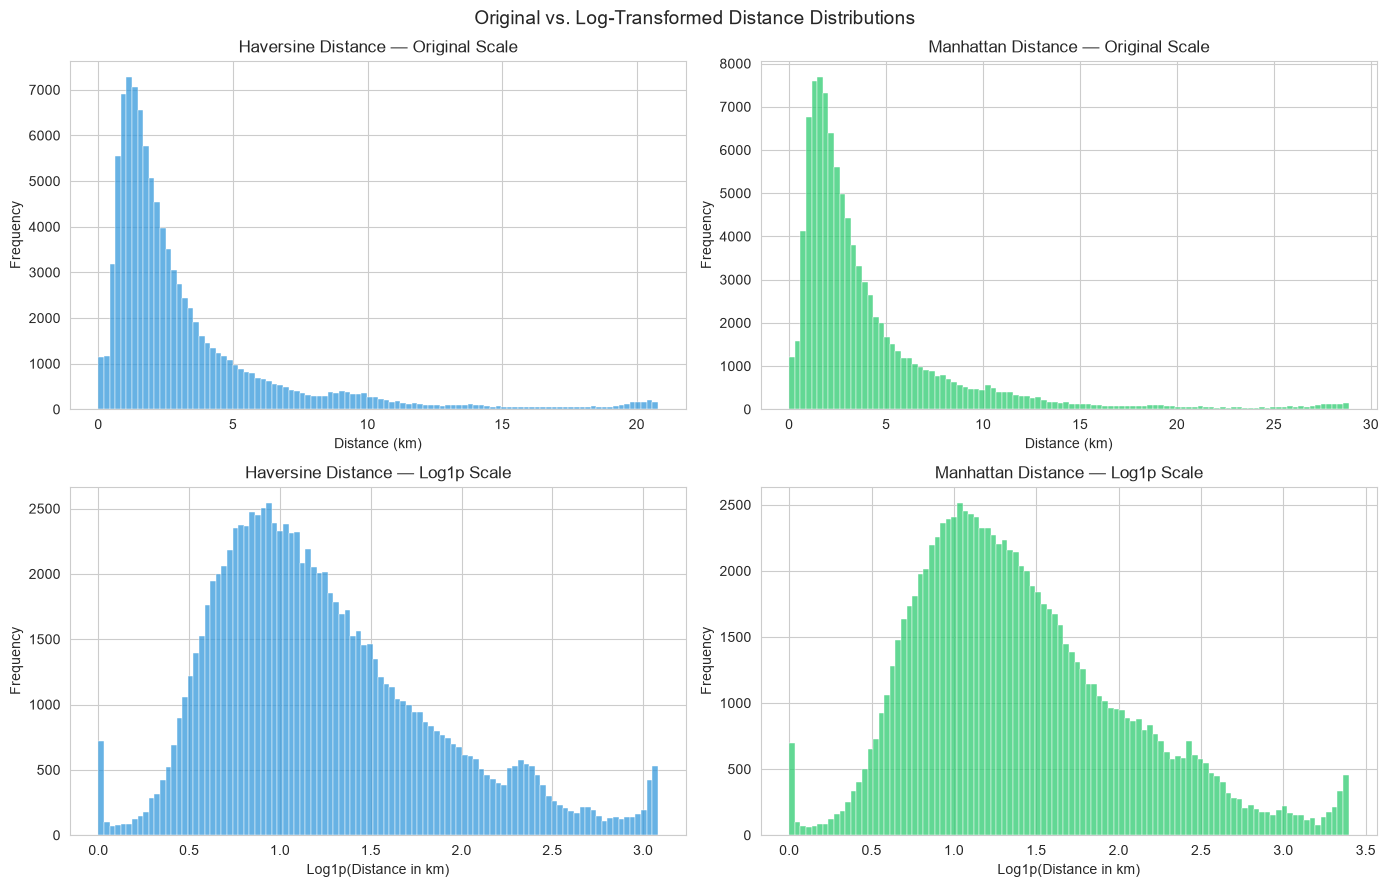

In [26]:
plot_distance_log_scaling(df)

In [27]:
display(summarize_log_distance_distributions(df).round(3))

valid_count  median     p95     p99   maximum  \
distance_feature   scale                                                     
haversine_distance Original      1000000   2.091  11.011  20.785  1240.909   
                   Log1p         1000000   1.129   2.486   3.081     7.124   
manhattan_distance Original      1000000   2.686  13.947  28.859  1328.091   
                   Log1p         1000000   1.305   2.705   3.396     7.192   

                             skewness  
distance_feature   scale               
haversine_distance Original    41.885  
                   Log1p        0.908  
manhattan_distance Original    34.780  
                   Log1p        0.824

##### Interpretation

Both Haversine and Manhattan-style distance exhibit strong right-skewness on the original scale. Applying `log1p` substantially reduces this skewness, from 41.885 to 0.908 for Haversine distance and from 34.780 to 0.824 for Manhattan-style distance. The transformed histograms show a more centralized distribution, making the spread of shorter and longer distances easier to inspect.

The transformation also compresses the extreme upper tail. The maximum Haversine distance decreases from 1,240.909 km to a log-transformed value of 7.124, while the maximum Manhattan-style distance decreases from 1,328.091 km to 7.192. However, these transformed maximum values remain above their respective 99th-percentile values of 3.081 and 3.396 on the log scale.

Both distance features respond similarly to the transformation, with their skewness falling below 1.0. Nevertheless, reduced skewness does not establish that either distribution is normally distributed.

The concentration of zero-distance observations remains because `log1p(0) = 0`. The transformation changes their scale representation but does not resolve or explain these records. Their validity requires separate investigation.

Overall, `log1p` provides a less skewed representation of both distance features and reduces the influence of extreme magnitudes on their numerical scale. Whether the transformed features improve Ridge Regression performance will be determined through validation experiments.

---

### Temporal Patterns

#### 1. Trip Duration by Pickup Hour, Day of the Week, and Month

Trip duration may vary with the time at which a journey begins. This analysis examines three temporal dimensions: pickup hour, day of the week, and month.

The median trip duration is used to examine typical trip duration within each group, while the 90th percentile provides additional information about longer trips. Observation counts are included to show how many trips support each summary.

The analysis uses the full training split. These summaries describe temporal patterns in the observed data but do not establish their causes or determine whether the corresponding features improve model performance.

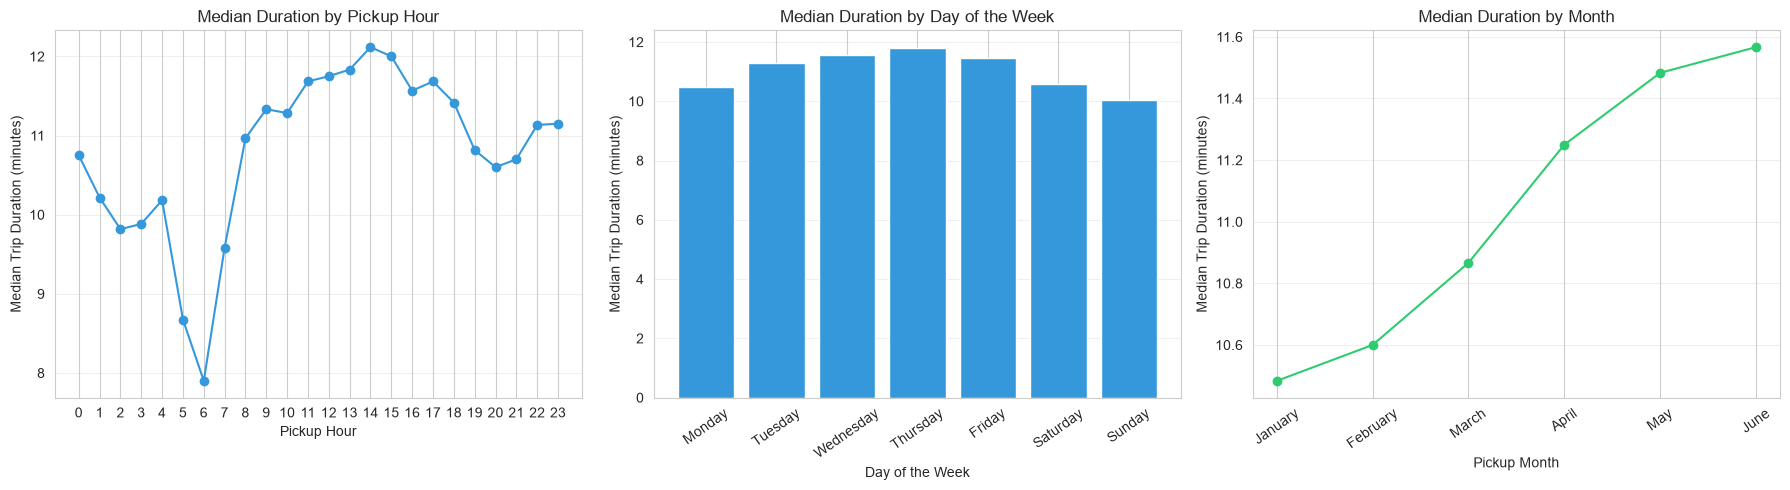

In [28]:
temporal_summaries = summarize_temporal_patterns(df)
plot_temporal_patterns(temporal_summaries)

In [29]:
display_temporal_summary(temporal_summaries)


Trip Duration by Pickup Hour


,trip_count,median_duration_minutes,p90_duration_minutes
pickup_hour,,,
0,36380,10.75,25.37
1,26666,10.22,23.65
2,19115,9.82,22.43
3,14360,9.88,22.62
4,10853,10.18,24.05
5,10232,8.68,25.70
6,22823,7.90,22.95
7,38061,9.58,23.80
8,46002,10.97,26.72



Trip Duration by Day of the Week


,trip_count,median_duration_minutes,p90_duration_minutes
Monday,128489,10.48,26.42
Tuesday,138794,11.30,27.90
Wednesday,144165,11.57,28.72
Thursday,149942,11.80,29.30
Friday,152835,11.47,28.08
Saturday,151454,10.57,24.87
Sunday,134321,10.03,24.85



Trip Duration by Month


,trip_count,median_duration_minutes,p90_duration_minutes
January,157629,10.48,25.50
February,163721,10.60,25.50
March,175745,10.87,26.40
April,172014,11.25,27.52
May,170499,11.48,29.15
June,160392,11.57,29.20


##### Interpretation

**Trip duration by pickup hour**

Median trip duration is lowest at 6:00 AM (7.90 minutes) and increases throughout the morning, reaching a peak of 12.12 minutes at 2:00 PM. The 90th-percentile duration peaks later, at 4:00 PM (33.90 minutes), indicating that the upper end of the duration distribution follows a different hourly pattern from the median.

Trip volume reaches its maximum at 6:00 PM, with 62,028 trips and a median duration of 11.42 minutes. Therefore, the hour with the highest number of trips does not coincide with the hour with the longest median duration.

**Trip duration by day of the week**

Median trip duration increases from 10.48 minutes on Monday to a weekly peak of 11.80 minutes on Thursday. Thursday also has the highest 90th-percentile duration, at 29.30 minutes.

Sunday has the lowest median duration, at 10.03 minutes, and the lowest 90th-percentile duration, at 24.85 minutes. Friday records the highest trip volume, with 152,835 trips. These results show that the observed duration distributions differ across days of the week.

**Trip duration by month**

Across the months represented in the training data, median trip duration increases from 10.48 minutes in January to 11.57 minutes in June. The 90th-percentile duration follows a similar pattern, rising from 25.50 minutes in January to 29.20 minutes in June.

Monthly trip counts remain relatively stable, ranging from approximately 157,000 to 175,000 observations. The increasing duration pattern occurs despite these relatively consistent monthly counts. However, because the observed period covers January through June, this analysis alone cannot establish a recurring annual seasonal pattern.

Overall, trip duration varies across pickup hours, days of the week, and the observed months. The median and 90th percentile do not always peak at the same time, showing why examining only typical trip duration would provide an incomplete picture. These patterns describe the training data; their causes and predictive value require further investigation.

---

#### 2. Weekday vs. Weekend Trip Duration

Trip duration may differ between weekdays and weekends. This analysis compares trips beginning Monday through Friday with those beginning on Saturday and Sunday.

For each group, the number of trips, median duration, and 90th-percentile duration are calculated. Comparing the median helps identify differences in typical trip duration, while the 90th percentile shows whether the longer trips also follow different patterns.

The analysis uses all valid observations in the training split. The results describe differences between the two groups but do not establish their causes.

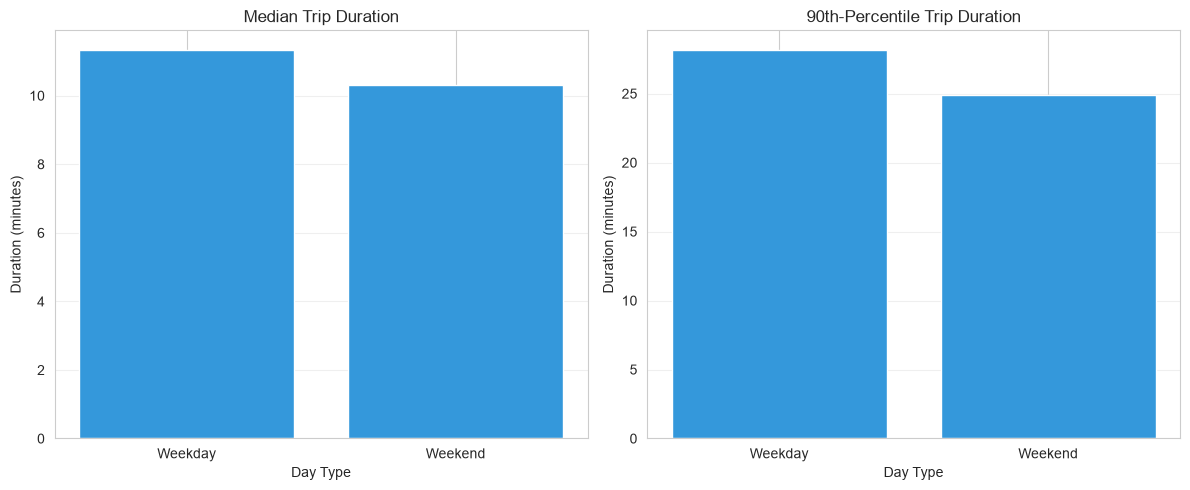

In [30]:
weekday_weekend_summary = summarize_weekday_weekend(df)
plot_weekday_weekend_patterns(weekday_weekend_summary)

In [31]:
display(weekday_weekend_summary.round(2))

,trip_count,median_duration_minutes,p90_duration_minutes
day_type,,,
Weekday,714225,11.33,28.17
Weekend,285775,10.32,24.87


##### Interpretation

Weekday trips have longer durations than weekend trips across both the median and 90th-percentile measures. The median duration decreases from 11.33 minutes on weekdays to 10.32 minutes on weekends, a difference of 1.01 minutes.

The 90th-percentile duration also decreases from 28.17 minutes on weekdays to 24.87 minutes on weekends. This indicates that longer trips, as represented by the 90th percentile, tend to have shorter durations on weekends as well.

The training data contains 714,225 weekday trips and 285,775 weekend trips. However, this difference in total counts must be interpreted in the context of the grouping: weekdays contain five days, whereas weekends contain only two. Comparing average trip counts per day would be more appropriate for evaluating differences in daily trip volume.

Overall, both typical trip duration and the upper end of the duration distribution are lower on weekends. These descriptive statistics establish a difference between the two groups but cannot identify its causes. The predictive value of the weekday–weekend distinction will be evaluated through validation experiments.

---

#### 3. Trip Duration During Rush Hours

Trip duration may vary depending on whether a trip begins during the rush-hour periods defined by the feature-engineering function.

This analysis compares rush-hour and non-rush-hour trips using the number of observations, their share of the dataset, mean duration, median duration, and 90th-percentile duration.

The mean represents the arithmetic average, the median describes the typical trip duration with less sensitivity to extreme values, and the 90th percentile provides information about longer trips.

The analysis uses the full training split and the existing `is_rush_hour` indicator. The results describe differences between the defined groups but do not establish their causes.

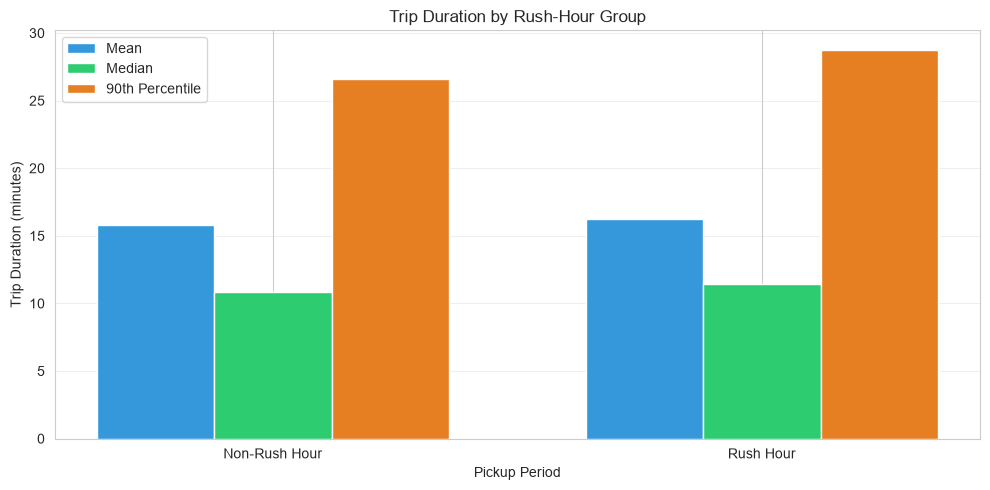

In [32]:
rush_hour_summary = summarize_rush_hour_patterns(df)
plot_rush_hour_patterns(rush_hour_summary)

In [33]:
display(rush_hour_summary.round(2))

,trip_count,trip_share_pct,mean_duration_minutes,median_duration_minutes,p90_duration_minutes
rush_hour_group,,,,,
Non-Rush Hour,698483,69.85,15.76,10.85,26.60
Rush Hour,301517,30.15,16.26,11.47,28.75


##### Interpretation

Trips classified as occurring during rush hours have slightly longer durations than non-rush-hour trips across all three duration measures. The mean duration is 16.26 minutes during rush hours, compared with 15.76 minutes outside rush hours. The median is 11.47 minutes versus 10.85 minutes, respectively.

The 90th-percentile duration is also higher during rush hours, reaching 28.75 minutes compared with 26.60 minutes during non-rush-hour periods. This indicates that the difference between the two groups is visible in both typical trip duration and the upper tail of the duration distribution.

Most trips occur outside the defined rush-hour periods. Non-rush-hour trips account for 698,483 observations (69.85%), while rush-hour trips account for 301,517 observations (30.15%).

For both groups, the mean duration exceeds the median, suggesting right-skewed duration distributions in which longer trips raise the arithmetic average. The difference between the median and 90th percentile also shows that durations vary considerably within each group.

Overall, trips classified as rush-hour trips tend to have longer durations in the observed training data. However, this comparison does not establish that traffic causes the difference. The results also depend on the specific hours and conditions used by the existing `is_rush_hour` definition. The predictive value of this feature will be evaluated through validation experiments.

---

#### 4. Cyclical Time Encodings

Hours and days of the week are periodic variables. The end of one period is adjacent to its beginning: hour 23 is followed by hour 0, and Sunday is followed by Monday.

This analysis examines the existing sine and cosine encodings for pickup hour and day of the week. Circular plots visualize the encoded values, while summary statistics compare the distances between neighboring encoded categories, including the transition from the final category back to the first.

The aim is to verify that the encodings preserve the intended periodic relationships, rather than to determine their predictive value.

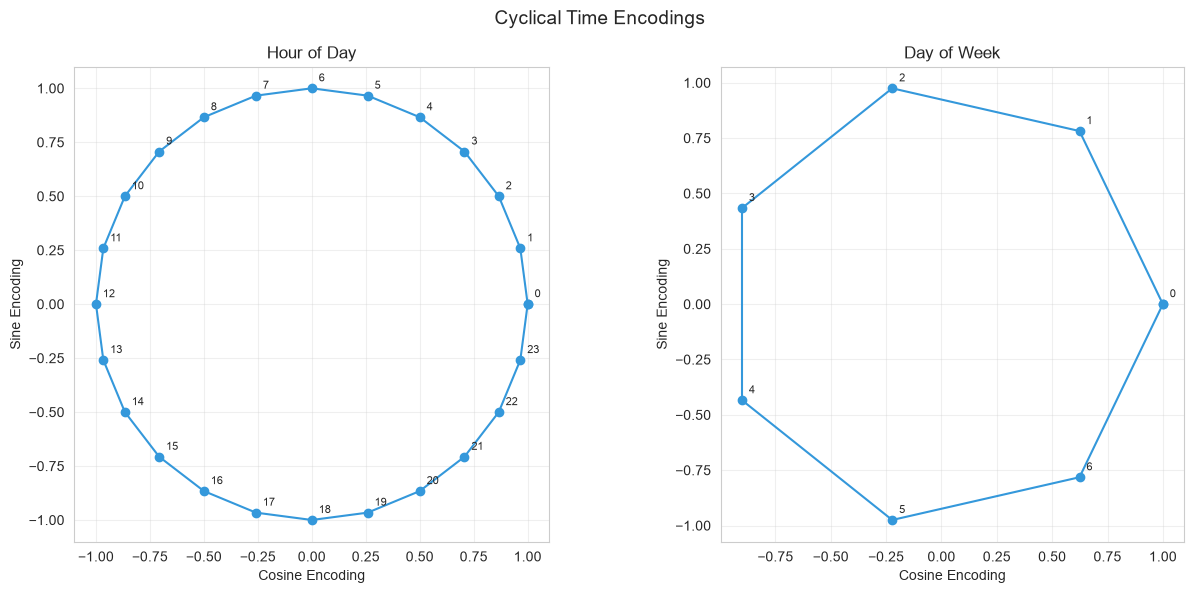

In [34]:
plot_cyclical_time_encodings(df)

In [35]:
display(summarize_cyclical_encodings(df).round(6))

,category_count,mean_neighbor_distance,min_neighbor_distance,max_neighbor_distance,first_to_second_distance,last_to_first_distance,wraparound_to_regular_ratio,raw_regular_gap,raw_wraparound_gap
time_cycle,,,,,,,,,
Pickup Hour,24,0.261052,0.261052,0.261052,0.261052,0.261052,1.0,1,23
Day of Week,7,0.867767,0.867767,0.867767,0.867767,0.867767,1.0,1,6


##### Interpretation

The cyclical encodings successfully represent pickup hour and day of the week in a two-dimensional space using sine and cosine transformations. The hour encoding forms a circle with 24 points, while the weekday encoding forms a regular seven-sided polygon.

The summary statistics confirm uniform distances between consecutive encoded categories. For pickup hour, the distance between neighboring points is approximately 0.261052, while for day of the week it is approximately 0.867767. In both cases, the distance from the final category back to the first is identical to the distance between ordinary neighboring categories, producing a wraparound-to-regular ratio of 1.0.

This representation addresses the boundary problem associated with raw numerical time features. For example, hours 23 and 0 are close together in the encoded space, as are Sunday and Monday. The cyclical features therefore preserve the periodic structure of these variables.

However, this analysis evaluates the mathematical structure of the encodings rather than the distribution of trip duration across time periods. It also does not establish that cyclical encoding performs better than alternative representations, such as one-hot encoding. Their predictive contribution must be evaluated through validation experiments.

Overall, the encodings represent the daily and weekly cycles consistently, including the transitions between the end and beginning of each period.

---

### Geographic Patterns

#### 1. Pickup and Drop-off Location Concentration

Pickup and drop-off coordinates can reveal where taxi trips are spatially concentrated. This analysis compares the geographic distributions of both endpoints to identify dense clusters and differences in their spatial coverage.

Hexbin plots summarize the number of observations within geographic regions, making them suitable for the large training dataset. Both plots use the same geographic window as the initial pickup-location visualization:

- Longitude: -74.5 to -73.3
- Latitude: 40.4 to 41.2

A summary table reports how many valid pickup and drop-off coordinate pairs fall inside and outside this window. Coordinates outside the displayed region are not automatically considered invalid; they require separate investigation.

The analysis uses the full training split rather than a random sample.

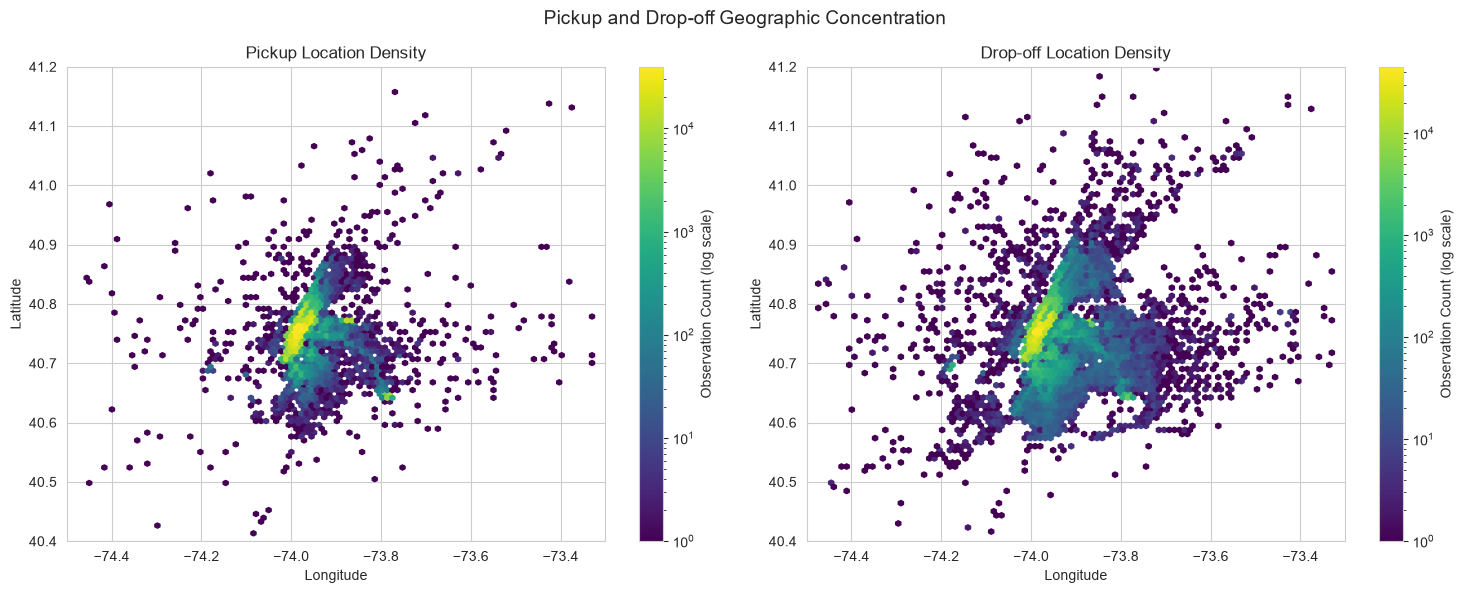

In [36]:
plot_pickup_dropoff_density(df)

In [37]:
display(summarize_location_coverage(df).round(2))

,valid_coordinate_pairs,within_window_count,within_window_pct,outside_window_count
location,,,,
Pickup,1000000,999950,100.00,50
Drop-off,1000000,999909,99.99,91


##### Interpretation

Both pickup and drop-off locations are concentrated within a relatively narrow geographic region, with the hexbin plots revealing a dense central core surrounded by areas with lower observation counts. The logarithmic color scale makes differences in spatial density easier to observe across the plotted region.

Drop-off locations appear more widely dispersed than pickup locations. This difference is also reflected in the coordinate-coverage summary, which identifies 91 drop-off coordinate pairs and 50 pickup coordinate pairs outside the selected geographic window.

The summary shows that 99.995% of pickup coordinate pairs and approximately 99.991% of drop-off coordinate pairs fall within the defined window. These results indicate that coordinates outside the selected region are rare in the training data.

However, falling outside this window does not automatically mean that a coordinate is invalid. The window defines the region displayed by the visualization, not a definitive boundary for valid taxi trips. Similarly, locations within the window may still contain inaccurate coordinates.

The plots show where pickup and drop-off observations are concentrated, but they do not identify specific neighborhoods or establish the routes traveled between locations. Further analysis is needed to investigate individual spatial patterns and determine whether unusual coordinates warrant closer examination.

Overall, both endpoints exhibit strong geographic concentration, with drop-off locations showing a slightly broader spatial distribution. Any decision to filter geographic observations should be based on explicit validity criteria rather than location outside the plotting window alone.

---

#### 2. Spatial Grid Frequency and Trip Duration

The spatial grid features group nearby pickup and drop-off coordinates into approximate geographic cells. This analysis examines whether certain cells occur more frequently than others and whether observed trip durations differ across the most frequently used cells.

The 15 most frequent pickup and drop-off grid cells are compared using trip counts, their percentage of valid observations, mean duration, median duration, and 90th-percentile duration.

The statistics are calculated from all valid training observations. The visualizations focus on the most frequent cells to make comparisons easier to interpret. These results describe observed spatial patterns but do not establish their causes or determine whether the grid features improve predictive performance.

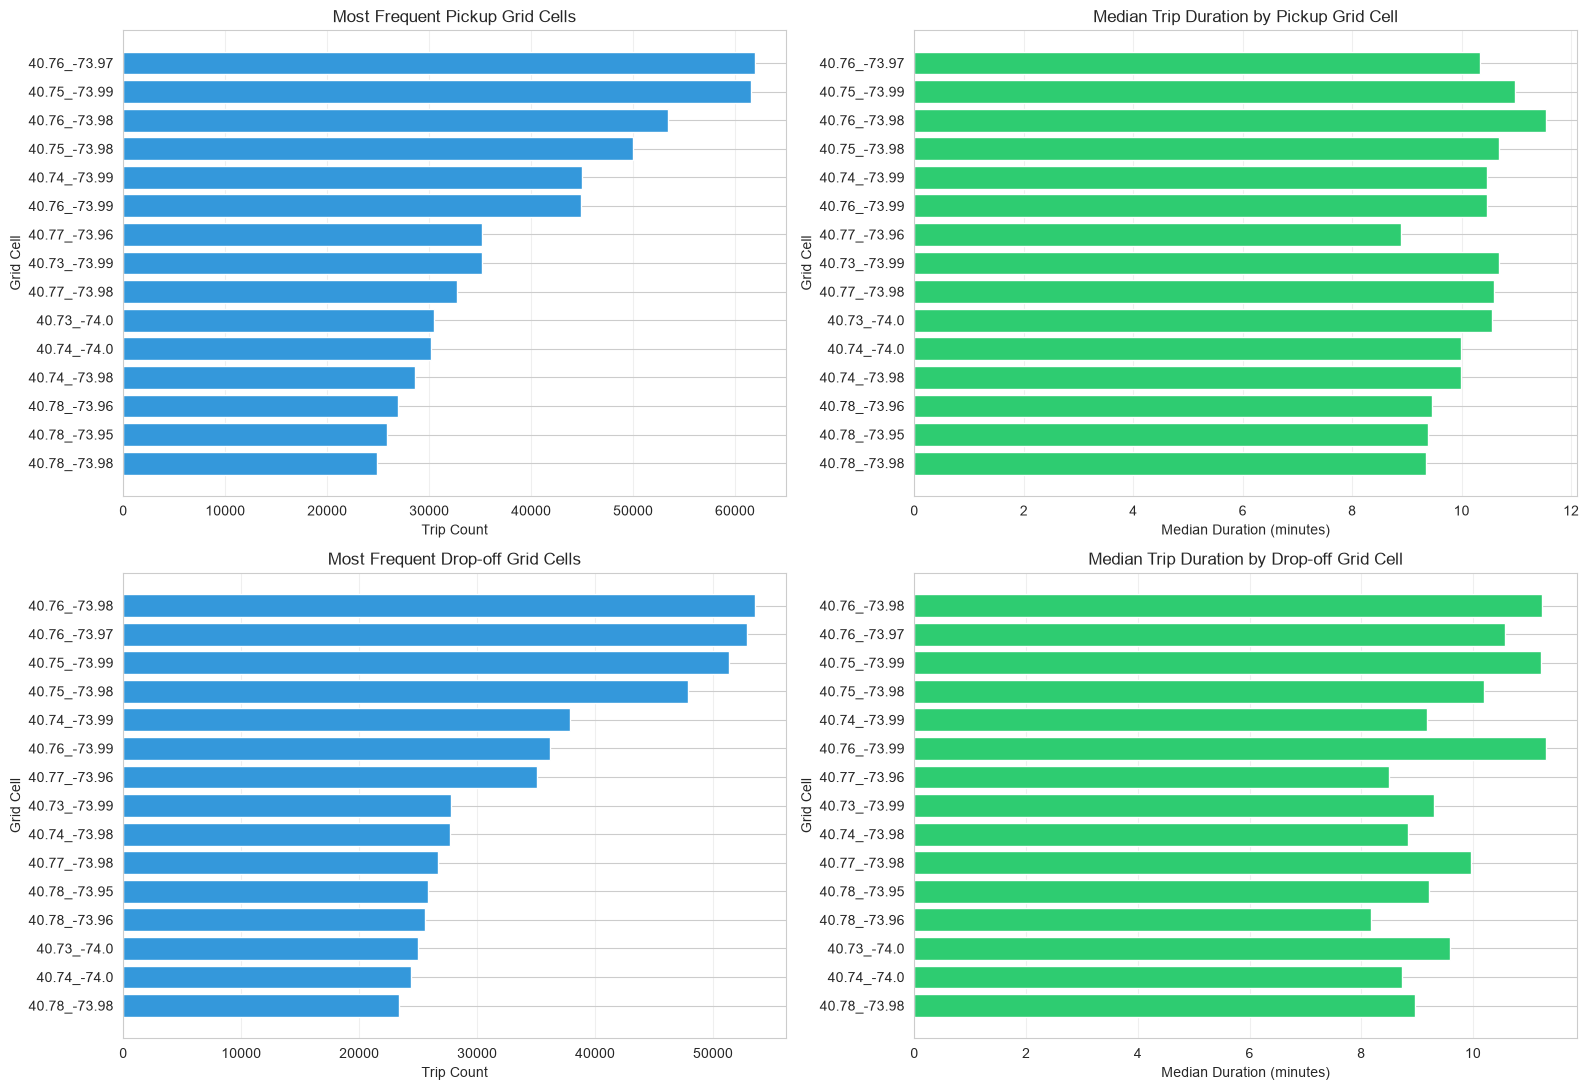

In [38]:
grid_summaries = summarize_spatial_grid_patterns(df, top_n=15)
plot_spatial_grid_patterns(grid_summaries)

In [39]:
for grid_name, summary in grid_summaries.items():
    print(f"\n{grid_name.replace('_', ' ').title()}")
    display(summary.round(2))


Pickup Grid


,grid_cell,trip_count,trip_share_pct,mean_duration_minutes,median_duration_minutes,p90_duration_minutes
0,40.76_-73.97,61908,6.19,14.19,10.33,23.25
1,40.75_-73.99,61606,6.16,15.61,10.98,25.25
2,40.76_-73.98,53456,5.35,16.53,11.53,26.78
3,40.75_-73.98,49973,5.00,14.38,10.68,23.40
4,40.74_-73.99,44965,4.50,14.76,10.47,23.93
5,40.76_-73.99,44904,4.49,15.15,10.47,25.62
6,40.77_-73.96,35209,3.52,12.62,8.90,22.38
7,40.73_-73.99,35156,3.52,14.96,10.68,23.90
8,40.77_-73.98,32756,3.28,14.70,10.58,24.15
9,40.73_-74.0,30432,3.04,14.95,10.55,24.72



Dropoff Grid


,grid_cell,trip_count,trip_share_pct,mean_duration_minutes,median_duration_minutes,p90_duration_minutes
0,40.76_-73.98,53518,5.35,16.26,11.23,27.58
1,40.76_-73.97,52898,5.29,14.82,10.57,23.68
2,40.75_-73.99,51373,5.14,15.70,11.22,24.85
3,40.75_-73.98,47877,4.79,14.47,10.20,22.93
4,40.74_-73.99,37848,3.78,13.35,9.18,21.42
5,40.76_-73.99,36204,3.62,16.95,11.30,27.10
6,40.77_-73.96,35048,3.50,12.04,8.50,20.52
7,40.73_-73.99,27810,2.78,14.31,9.30,21.20
8,40.74_-73.98,27714,2.77,12.20,8.83,19.68
9,40.77_-73.98,26694,2.67,14.02,9.97,23.05


##### Interpretation

Trip activity is concentrated in a relatively small number of spatial grid cells. The most frequent pickup cell, `40.76_-73.97`, accounts for 61,908 trips (6.19% of the training dataset), while the most frequent drop-off cell, `40.76_-73.98`, accounts for 53,518 trips (5.35%). The sharp decline in counts across the top 15 cells indicates that trip activity is not distributed uniformly across locations.

Several of these grid cells correspond approximately to well-known areas of Manhattan, including areas near major landmarks, commercial districts, and transportation hubs. However, the coordinates are rounded to two decimal places, so each grid represents an approximate geographic area rather than an exact landmark or address.

Median trip durations vary across the most frequent cells. For pickup grids, the median ranges from 8.90 to 11.53 minutes, while for drop-off grids it ranges from 8.18 to 11.30 minutes. The 90th-percentile durations reach 26.78 minutes for pickup grids and 27.58 minutes for drop-off grids, indicating that longer trips also occur within these frequently used areas.

The most popular grid cells do not necessarily have the longest or shortest median trip durations. This suggests that location frequency and typical trip duration represent different aspects of taxi activity. However, these summaries alone cannot explain why durations vary or establish whether a particular landmark contributes to a cell's popularity.

Overall, the spatial grid features reveal geographic concentrations and differences in observed trip durations across frequently used locations. Further analysis of pickup–drop-off grid pairs could help investigate how origin and destination combinations relate to trip duration. The predictive value of these features will ultimately be assessed through validation experiments.

---

#### 3. Extreme Distances and Potentially Suspicious Coordinates

The distance-distribution analysis identified observations with unusually large geographic distances. This section investigates whether these extreme distances are associated with pickup or drop-off coordinates outside the geographic window used in the earlier analysis.

Trips above the 99th percentile of Haversine distance are examined as the extreme-distance group. Their coordinate coverage is compared with that of all valid trips, and the records with the largest distances are inspected individually.

The geographic window is used as a diagnostic reference, not as a definitive boundary for valid trips. Coordinates outside it may warrant investigation, but their exclusion should depend on explicit validity criteria rather than distance alone.

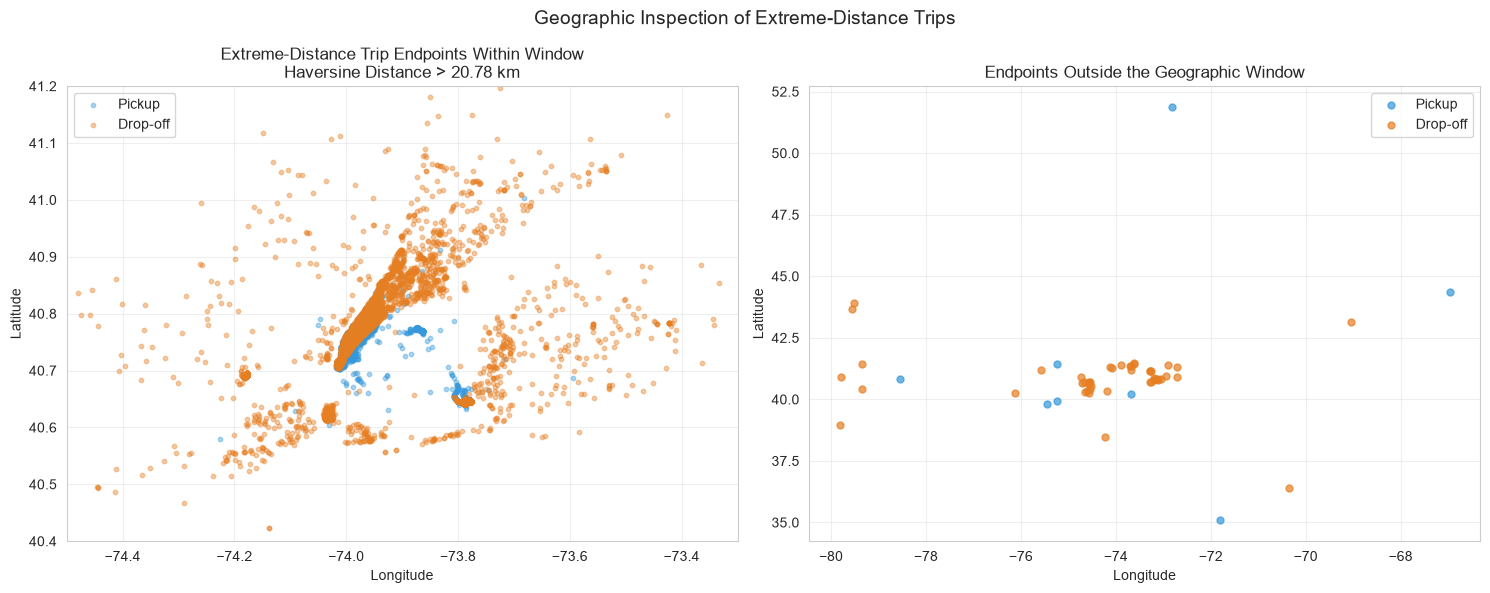

In [40]:
plot_extreme_distance_coordinates(df, percentile=99)

In [41]:
extreme_distance_results = summarize_extreme_distance_coordinates(
    df,
    percentile=99,
    top_n=10,
)

display(extreme_distance_results["summary"].round(3))

,trip_count,share_of_valid_trips_pct,distance_threshold_km,median_haversine_km,maximum_haversine_km,pickup_outside_count,pickup_outside_pct,dropoff_outside_count,dropoff_outside_pct,either_endpoint_outside_count,either_endpoint_outside_pct
group,,,,,,,,,,,
All valid trips,1000000,100.0,20.785,2.091,1240.909,50,0.005,91,0.009,96,0.01
Above 99th percentile,10000,1.0,20.785,21.561,1240.909,8,0.080,50,0.500,54,0.54


In [42]:
display(extreme_distance_results["top_examples"].round(6))

,id,haversine_distance,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,pickup_outside_window,dropoff_outside_window
0,id2306955,1240.908677,-72.809669,51.881084,-73.987228,40.750599,True,False
1,id1510552,891.214103,-71.799896,35.081532,-79.352837,40.436329,True,True
2,id1146400,578.842818,-73.989914,40.756634,-70.346077,36.398121,False,True
3,id2644780,574.875442,-73.991325,40.750023,-79.518616,43.921028,False,True
4,id1001696,562.235188,-73.972366,40.758633,-79.553535,43.674000,False,True
5,id0982904,545.853499,-73.870682,40.773598,-79.817978,38.963852,False,True
6,id3626673,455.241204,-73.978912,40.756763,-79.338699,41.427902,False,True
7,id0401529,254.363523,-73.980751,40.757111,-74.240051,38.478298,False,True
8,id0838705,215.226573,-66.972160,44.371944,-69.048019,43.147583,True,True
9,id1216866,191.402792,-73.981491,40.773251,-76.135719,40.243626,False,True


##### Interpretation

The analysis identifies 10,000 trips above the 99th percentile of Haversine distance, corresponding to a threshold of approximately 20.785 km. Although these trips represent only 1% of the training dataset, they contain a substantial proportion of the observations with coordinates outside the predefined geographic window.

Among the extreme-distance trips, 54 have at least one endpoint outside the window. This represents more than half of the 96 trips identified as having at least one endpoint outside the window across the full dataset. Therefore, extreme-distance trips are disproportionately associated with unusual geographic coordinates.

The coordinate summary also reveals a difference between pickup and drop-off locations within this subset. Eight pickup coordinates and 50 drop-off coordinates fall outside the window. The plotted endpoints extend well beyond the main NYC region, with some observations reaching locations hundreds of kilometers away.

The largest recorded Haversine distance is 1,240.909 km, which is highly unusual for a dataset of NYC taxi trips. Such observations are strong candidates for further data-quality investigation. However, the distance and coordinate plots alone cannot establish whether an individual record results from a GPS error, an incorrect record, or another cause.

Overall, the analysis shows that extreme distances are associated with a disproportionate share of geographically unusual observations, particularly at drop-off locations. These findings justify investigating explicit geographic and distance-based validity criteria. However, observations should not be removed solely because they exceed the 99th percentile or fall outside the plotting window. Any filtering rule should be documented and evaluated through controlled validation experiments before being adopted for modeling.

---

### Airport Proximity and Direction

#### 1. Trip Duration by Airport Proximity

Trips near airport reference points may have different duration patterns from trips farther away. This analysis examines the relationship between trip duration and the geographic distance from each pickup and drop-off location to the selected airport reference coordinates: JFK, LaGuardia, and Newark.

For each of the six airport-distance features, trips are grouped into fixed distance bands: 0–2 km, over 2–5 km, over 5–10 km, over 10–20 km, and over 20 km.

The summary includes the number of trips, their share of valid observations, mean duration, median duration, and 90th-percentile duration. The plots compare median trip duration across the distance bands.

Airport distances represent geographic proximity to reference points, not road distance or confirmation that a trip begins or ends at an airport. The results describe observed relationships and do not establish their causes.

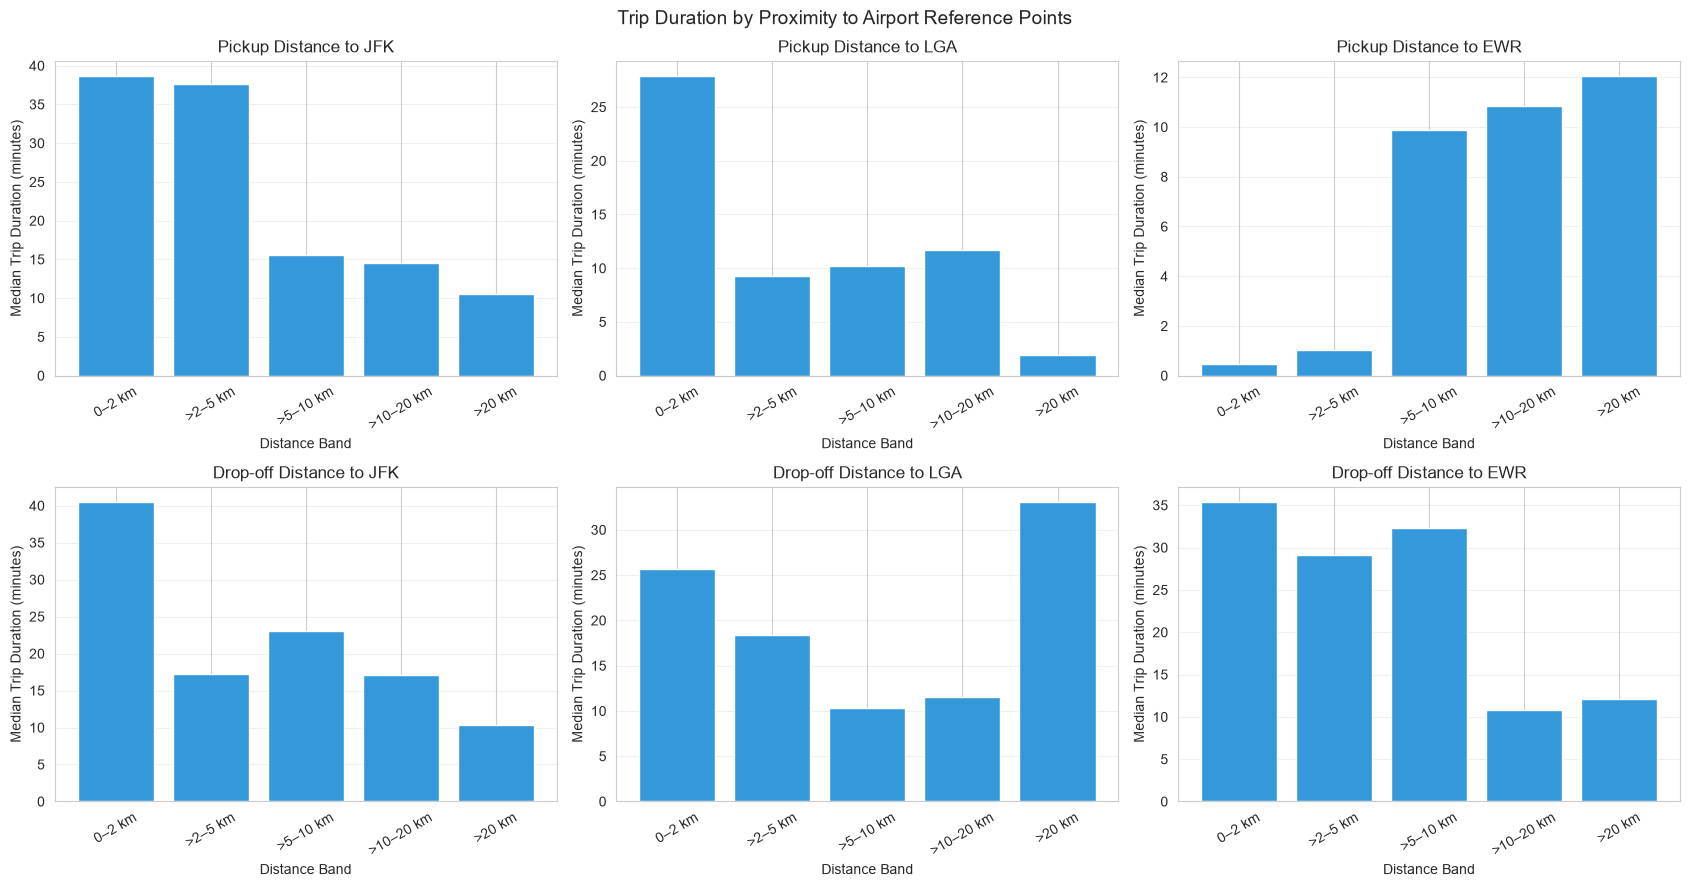

In [43]:
airport_summaries = summarize_airport_proximity(df)
plot_airport_proximity_patterns(airport_summaries)

In [44]:
for feature, summary in airport_summaries.items():
    print(f"\n{feature.replace('_', ' ').title()}")
    display(summary.round(2))


Pickup Jfk Distance


,trip_count,trip_share_pct,mean_duration_minutes,median_duration_minutes,p90_duration_minutes
distance_band,,,,,
0–2 km,21561,2.16,42.55,38.70,65.05
>2–5 km,670,0.07,41.64,37.63,67.04
>5–10 km,599,0.06,20.93,15.55,44.63
>10–20 km,97414,9.74,19.95,14.57,35.63
>20 km,879756,87.98,14.79,10.53,24.52



Pickup Lga Distance


,trip_count,trip_share_pct,mean_duration_minutes,median_duration_minutes,p90_duration_minutes
distance_band,,,,,
0–2 km,25382,2.54,32.22,27.92,48.75
>2–5 km,5136,0.51,14.49,9.28,24.93
>5–10 km,542712,54.27,14.29,10.17,23.85
>10–20 km,426225,42.62,17.03,11.70,28.98
>20 km,545,0.05,9.64,1.93,22.11



Pickup Ewr Distance


...

,trip_count,trip_share_pct,mean_duration_minutes,median_duration_minutes,p90_duration_minutes
distance_band,,,,,
0–2 km,8132,0.81,45.89,40.54,69.66
>2–5 km,1550,0.16,28.18,17.24,56.18
>5–10 km,3121,0.31,30.15,23.05,45.65
>10–20 km,134166,13.42,21.51,17.07,35.48
>20 km,853031,85.30,14.67,10.28,24.30



Dropoff Lga Distance


,trip_count,trip_share_pct,mean_duration_minutes,median_duration_minutes,p90_duration_minutes
distance_band,,,,,
0–2 km,12904,1.29,29.54,25.67,43.28
>2–5 km,15177,1.52,21.17,18.40,33.43
>5–10 km,561622,56.16,14.67,10.28,24.50
>10–20 km,404970,40.50,16.72,11.53,28.52
>20 km,5327,0.53,37.97,33.12,55.77



Dropoff Ewr Distance


,trip_count,trip_share_pct,mean_duration_minutes,median_duration_minutes,p90_duration_minutes
distance_band,,,,,
0–2 km,1840,0.18,41.95,35.43,56.40
>2–5 km,58,0.01,33.08,29.18,54.62
>5–10 km,234,0.02,44.54,32.26,65.10
>10–20 km,743629,74.36,15.28,10.75,25.32
>20 km,254239,25.42,17.55,12.07,31.73


##### Interpretation

Trip duration varies across the distance bands associated with the three airport reference points. For JFK and LaGuardia, trips with pickup or drop-off locations within 2 km of the reference coordinates generally exhibit higher median durations than trips in several more distant bands. However, the pattern is not uniform across every airport and endpoint.

The distance-band summaries also show that most trips occur far from the airport reference points. More than 20 km from JFK accounts for 87.98% of pickups and 85.30% of drop-offs. Proximity to Newark is particularly uncommon on the pickup side, with only 88 trips recorded within 2 km of the EWR reference point.

The upper tail of the duration distribution varies considerably across the bands. For pickups within 2 km of JFK, the 90th-percentile duration reaches 65.05 minutes. For drop-offs more than 20 km from LaGuardia, the median duration reaches 33.12 minutes and the 90th percentile reaches 55.77 minutes.

Newark shows a particularly unusual difference between its nearest pickup and drop-off bands. Drop-offs within 2 km of the EWR reference point have a median duration of 35.43 minutes, while the 88 pickups in that band have a median of only 0.48 minutes. Because the pickup group is small and its result is unusually low, this finding should be checked against the underlying records before drawing conclusions about the trips or their origins.

These distance bands describe straight-line proximity to fixed airport reference coordinates. They do not confirm that a passenger is traveling to or from an airport, and they do not account for road distance, bridge access, or route restrictions. Differences in duration should therefore be interpreted as observed associations rather than evidence that airport proximity causes longer trips.

Overall, the airport-distance features reveal differences in trip-duration distributions across geographic bands, but those differences vary by airport and endpoint. The rare observations near EWR and the long-duration tails warrant closer inspection. Whether these features improve prediction, particularly for less frequently represented distance bands, must be evaluated through validation experiments.

---

#### 2. Pickup Bearing, Distance, and Identical Endpoints

Pickup bearing describes the initial compass direction from the pickup location toward the drop-off location. This analysis examines the distribution of trip directions and compares geographic distances across directional groups.

The trips are grouped into eight compass sectors: north, northeast, east, southeast, south, southwest, west, and northwest. For each sector, the analysis reports trip counts, median geographic distances, and trip-duration summaries.

The analysis also identifies trips whose pickup and drop-off coordinates are exactly identical. Such records have zero endpoint separation, and their direction is mathematically undefined even if the bearing calculation returns a numerical value.

The summaries use the valid training observations. These checks describe the distribution and identify records for further investigation; they do not establish whether a trip is erroneous or whether its engineered features improve model performance.

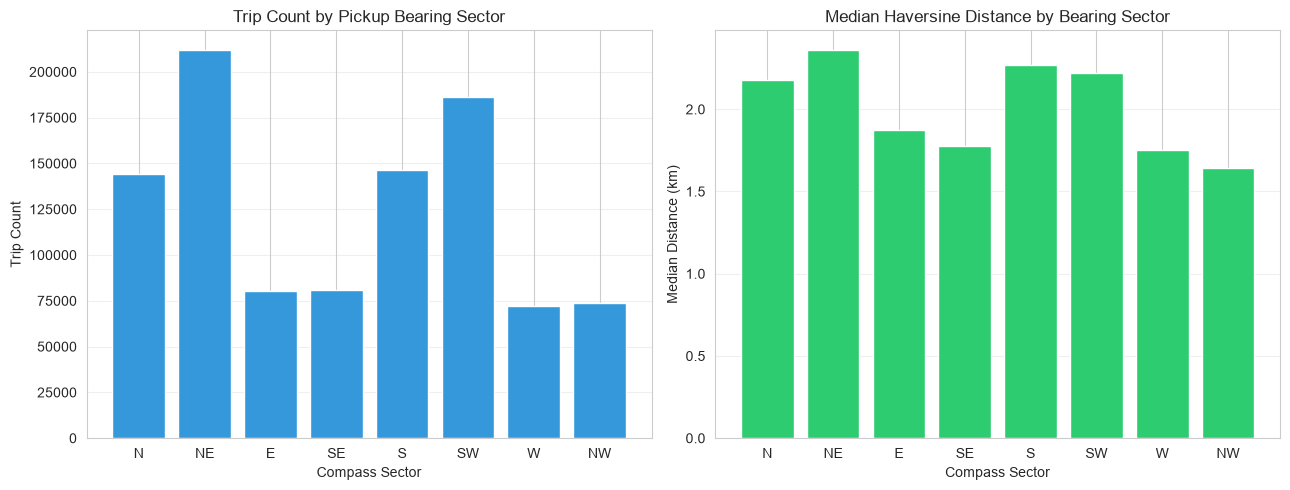

In [45]:
bearing_distance_summaries = summarize_bearing_distance_patterns(df)
plot_bearing_distance_patterns(bearing_distance_summaries)

In [46]:
display(bearing_distance_summaries["overview"].round(3))

,valid_trip_count,identical_endpoint_count,identical_endpoint_pct,zero_haversine_count,zero_manhattan_count,haversine_median_km,haversine_p95_km,haversine_p99_km,haversine_max_km,manhattan_median_km,manhattan_p95_km,manhattan_p99_km,manhattan_max_km,identical_endpoint_median_duration_min,identical_endpoint_p90_duration_min
0,1000000,4085,0.409,4085,4085,2.091,11.011,20.785,1240.909,2.686,13.947,28.859,1328.091,5.9,20.0


In [47]:
display(bearing_distance_summaries["by_bearing_sector"].round(2))

,trip_count,median_haversine_km,median_manhattan_km,trip_share_pct,median_duration_minutes,p90_duration_minutes
bearing_sector,,,,,,
N,144072,2.18,2.55,14.47,10.80,23.85
NE,211981,2.36,3.25,21.29,10.50,23.80
E,80510,1.88,2.20,8.08,11.78,28.97
SE,80802,1.78,2.45,8.11,10.97,33.33
S,146411,2.27,2.66,14.70,11.87,26.70
SW,186257,2.22,3.06,18.70,10.97,24.70
W,72314,1.75,2.06,7.26,12.00,37.70
NW,73568,1.64,2.26,7.39,10.22,43.53


##### Interpretation

The directional analysis reveals that taxi trips are not distributed evenly across compass sectors. The Northeast (NE) sector has the highest trip count, with 211,981 trips representing 21.29% of the observations included in the directional summary. Southwest (SW) is the second most frequent sector, accounting for 18.70%. In contrast, West (W) and Northwest (NW) are the least frequent, representing 7.26% and 7.39%, respectively.

Median Haversine distance varies across directions. Northeast and South trips have the largest median distances, at 2.36 km and 2.27 km, respectively. Northwest and West trips have shorter median distances of 1.64 km and 1.75 km. Despite these differences in distance, median trip duration remains relatively consistent across the eight compass sectors, ranging from 10.22 minutes for Northwest trips to 12.00 minutes for West trips. The 90th-percentile durations show greater variation, reaching 43.53 minutes for Northwest trips and 37.70 minutes for West trips. This suggests that the upper tail of the duration distribution varies more across directions than the median does.

The coordinate analysis also identifies 4,085 trips with identical recorded pickup and drop-off coordinates, representing 0.409% of the one million training observations. Both Haversine and Manhattan-style distance calculations return zero for these records. Despite having no geographic separation between their recorded endpoints, these trips have non-zero recorded durations. Their median duration is 5.9 minutes, while the 90th percentile reaches 20.0 minutes, indicating considerable variation within this subset.

Compared with the full training dataset, where the median Haversine distance is 2.091 km and the median Manhattan-style distance is 2.686 km, these records form a distinct group with zero calculated distance. The dataset also contains extreme distances exceeding 1,200 km, indicating unusual observations at both ends of the distance distribution.

Pickup bearing represents the initial straight-line direction from the pickup coordinates to the drop-off coordinates. It does not describe the actual route taken through the street network. Similarly, identical recorded coordinates do not prove that a vehicle remained stationary or that a GPS failure occurred. The available summaries cannot establish the causes of these patterns.

Overall, compass sectors differ in trip frequency, median geographic distance, and upper-tail duration, while a small subset of trips has zero geographic separation despite substantial recorded durations. These observations warrant further investigation, but they do not establish whether bearing provides additional predictive information or whether the zero-distance records should be removed. Any filtering decisions and the predictive contribution of these features should be evaluated through controlled validation experiments.

---

### Categorical Features and Feature Relationships

#### 1. Trip Duration by Vendor, Store-and-Forward Flag, and Day–Hour Category

This analysis examines how trip duration varies across three categorical features: `vendor_id`, `store_and_fwd_flag`, and the engineered `day_hour` category.

For each group, the summary reports the number of trips, its share of valid observations, mean duration, median duration, and 90th-percentile duration. The mean describes the arithmetic average, the median represents typical trip duration with less sensitivity to extreme values, and the 90th percentile describes the upper tail of the duration distribution.

For `day_hour`, the visualization focuses on the 15 most frequent categories to keep comparisons readable. The analysis describes observed differences between groups but does not establish their causes or determine whether these features improve predictive performance.

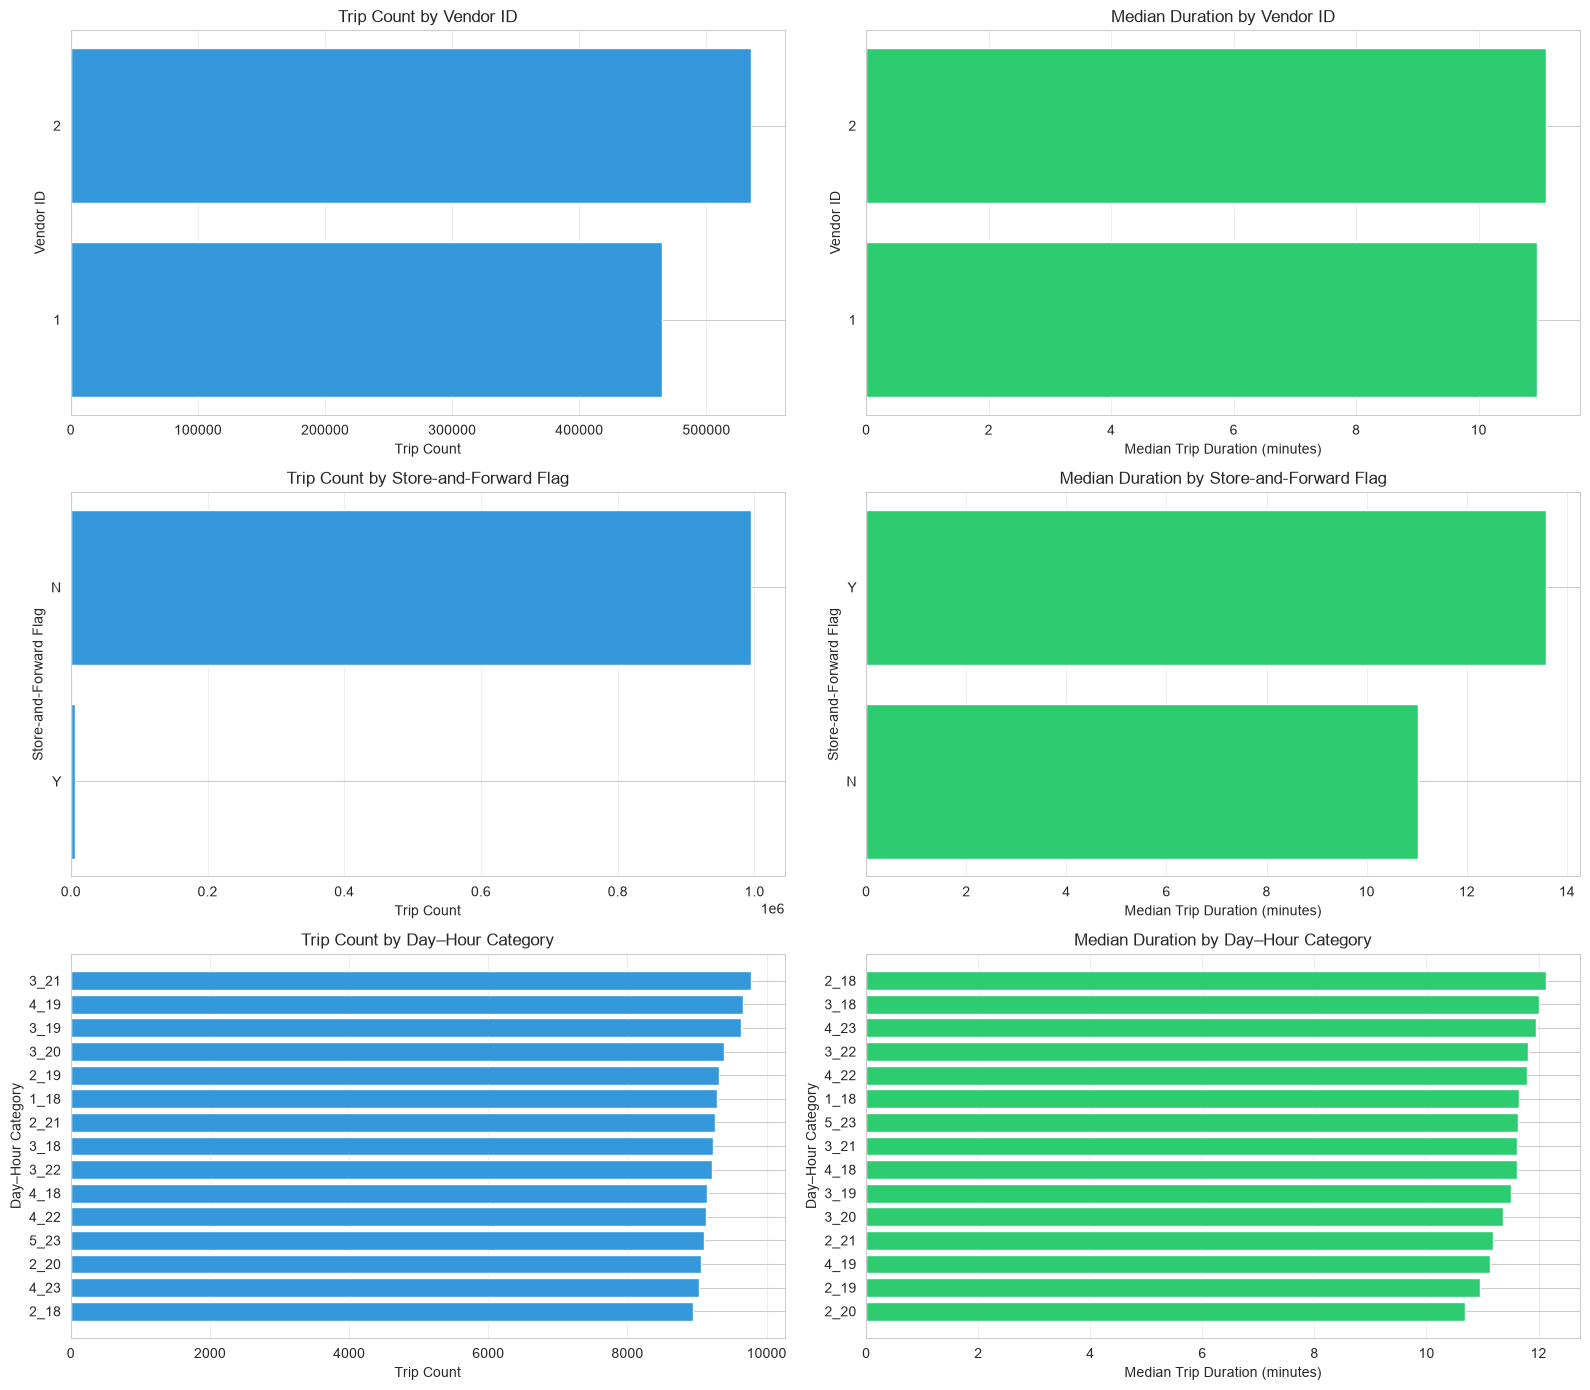

In [48]:
categorical_summaries = summarize_categorical_duration(
    df,
    top_n=15,
)

plot_categorical_duration_patterns(categorical_summaries)

In [49]:
for feature, summary in categorical_summaries.items():
    print(f"\n{feature.replace('_', ' ').title()}")
    display(summary.round(2))


Vendor Id


,trip_count,trip_share_pct,mean_duration_minutes,median_duration_minutes,p90_duration_minutes
vendor_id,,,,,
1,465207,46.52,13.92,10.95,26.85
2,534793,53.48,17.65,11.10,27.52



Store And Fwd Flag


,trip_count,trip_share_pct,mean_duration_minutes,median_duration_minutes,p90_duration_minutes
store_and_fwd_flag,,,,,
N,994443,99.44,15.90,11.02,27.13
Y,5557,0.56,17.93,13.58,37.40



Day Hour


,trip_count,trip_share_pct,mean_duration_minutes,median_duration_minutes,p90_duration_minutes
day_hour,,,,,
3_21,9771,0.98,16.03,11.62,27.18
4_19,9668,0.97,15.36,11.14,24.94
3_19,9627,0.96,15.38,11.52,26.38
3_20,9390,0.94,15.13,11.37,25.43
2_19,9312,0.93,14.44,10.95,25.55
1_18,9291,0.93,15.66,11.65,27.47
2_21,9257,0.93,15.21,11.18,25.40
3_18,9237,0.92,16.69,12.00,30.47
3_22,9219,0.92,16.92,11.82,27.55


##### Interpretation

**Vendor ID**

Trip counts are relatively balanced between the two vendors. Vendor 2 accounts for 534,793 trips (53.48%), while Vendor 1 accounts for 465,207 trips (46.52%).

Despite their similar median trip durations, approximately 11.0–11.1 minutes, the vendors have noticeably different mean durations. Vendor 2 has a mean of 17.65 minutes, compared with 13.92 minutes for Vendor 1. This difference, alongside the similar medians, suggests that the duration distributions differ particularly in their upper tails. However, these summaries alone do not establish the cause of the difference.

**Store-and-forward flag**

The store-and-forward flag is highly imbalanced. Most trips are marked `N`, representing 994,443 observations (99.44%), while 5,557 trips (0.56%) are marked `Y`.

Trips marked `Y` have a mean duration of 17.93 minutes and a 90th-percentile duration of 37.40 minutes. For trips marked `N`, these values are 15.90 and 27.13 minutes, respectively. The higher mean and 90th percentile for the `Y` group indicate longer observed durations, particularly toward the upper tail. However, the small number of `Y` observations should be considered when interpreting this difference.

**Day–hour categories**

The engineered `day_hour` feature combines the pickup day of the week and the pickup hour into a single categorical variable. Individual categories account for approximately 0.9% to 1.0% of the dataset, while some combinations exhibit higher mean durations. For example, category `2_18` has a mean duration of 17.38 minutes.

These differences suggest that trip-duration distributions vary across day–hour combinations. However, a higher mean does not necessarily imply a higher median, and categories should be compared using their observation counts alongside their duration statistics.

Overall, vendor ID, the store-and-forward flag, and day–hour categories show differences in observed trip durations and frequency. These features provide alternative categorical representations of provider, record status, and pickup timing. The descriptive statistics do not establish the operational causes of these differences or prove that the features improve Ridge Regression performance. Their predictive contribution will be evaluated through controlled validation experiments.

---

#### 2. Spatial Category Frequency and Sparsity

Spatial grid features represent pickup locations, drop-off locations, and combinations of pickup–drop-off grid cells. Their usefulness for analysis depends partly on how frequently each category occurs.

This analysis examines the number of distinct categories, the distribution of observations across categories, and the proportion of observations belonging to infrequent categories.

Category frequencies are summarized in bands, and the most frequent categories are visualized for comparison. Categories with fewer than 10 observations and fewer than 50 observations are examined as diagnostic groups; these thresholds are used for description rather than treated as universal definitions of sparsity.

The summaries use all available training observations. A category with few observations may have an unstable duration summary, while a frequently observed category is not necessarily predictive of trip duration.

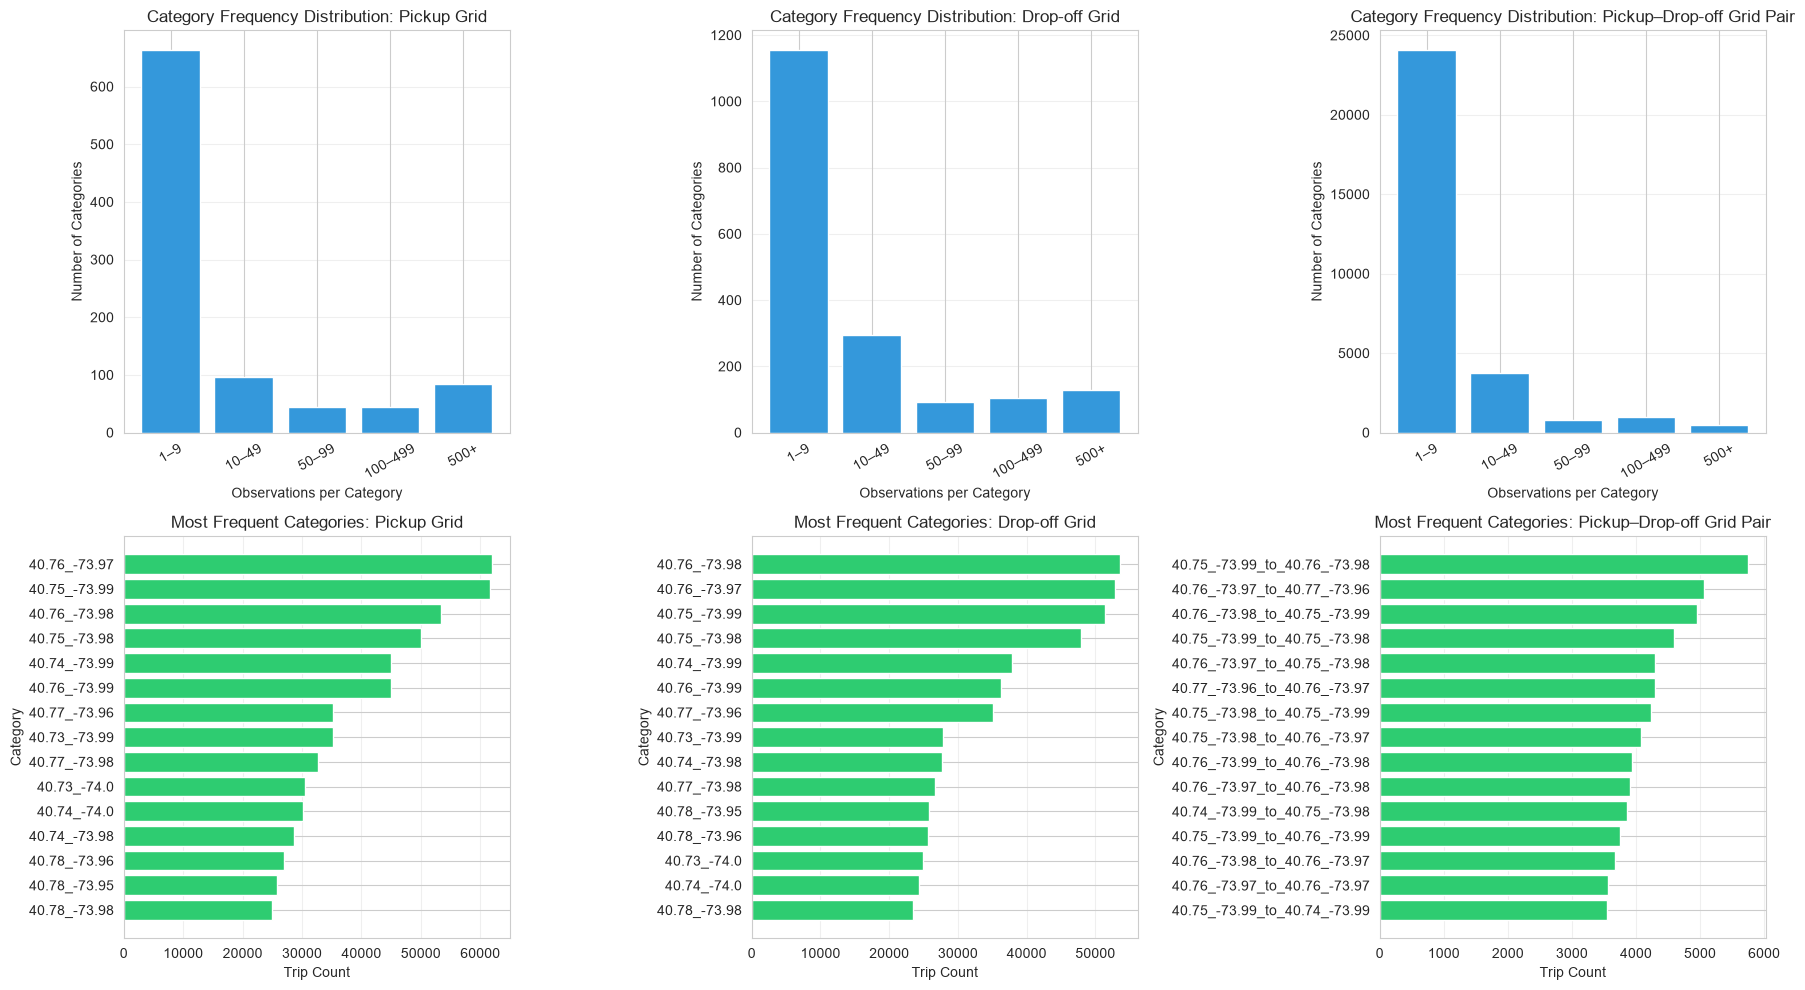

In [50]:
spatial_sparsity = summarize_spatial_category_sparsity(
    df,
    top_n=15,
    rare_threshold=10,
)

plot_spatial_category_sparsity(spatial_sparsity)

In [51]:
display(spatial_sparsity["overview"].round(2))

,valid_observations,unique_categories,single_observation_categories,median_category_frequency,p90_category_frequency,maximum_category_frequency,categories_below_threshold,observations_in_rare_categories,rare_observation_share_pct,categories_below_50,observations_in_categories_below_50,observations_below_50_share_pct
category_feature,,,,,,,,,,,,
pickup_grid,1000000,936,410,2.0,351.5,61908,664,1408,0.14,761,3586,0.36
dropoff_grid,1000000,1778,677,3.0,218.0,53518,1156,2497,0.25,1451,9710,0.97
pickup_dropoff_grid,1000000,30075,13252,2.0,31.0,5741,24098,54345,5.43,27822,134694,13.47


In [52]:
display(spatial_sparsity["frequency_bands"].round(2))

,frequency_band,category_count,observation_count,observation_share_pct,category_feature
0,1–9,664,1408,0.14,pickup_grid
1,10–49,97,2178,0.22,pickup_grid
2,50–99,45,3197,0.32,pickup_grid
3,100–499,45,11351,1.14,pickup_grid
4,500+,85,981866,98.19,pickup_grid
5,1–9,1156,2497,0.25,dropoff_grid
6,10–49,295,7213,0.72,dropoff_grid
7,50–99,93,6593,0.66,dropoff_grid
8,100–499,105,24036,2.40,dropoff_grid
9,500+,129,959661,95.97,dropoff_grid


##### Interpretation

The spatial grid features exhibit highly uneven category frequencies. A small number of frequently observed categories account for most trips, while many other categories occur only a few times.

For individual grid cells, categories appearing at least 500 times account for 98.19% of pickup observations and 95.97% of drop-off observations. In contrast, the lowest frequency band, containing categories observed between one and nine times, includes 664 pickup-grid categories and 1,156 drop-off-grid categories. These rare categories account for only 0.14% and 0.25% of their respective observations.

Sparsity increases substantially for the combined `pickup_dropoff_grid` feature. It contains 30,075 unique pickup–drop-off grid pairs, including 13,252 pairs observed exactly once. Furthermore, 24,098 pairs occur fewer than 10 times, collectively accounting for 54,345 trips (5.43% of the dataset). Only 59.80% of observations belong to route pairs appearing at least 500 times.

These results show that individual pickup and drop-off grids are more concentrated than the combined route feature. Combining both endpoints creates a much larger number of distinct categories, many of which have limited observational support.

However, low frequency does not automatically mean that a category is invalid or useless. Rare categories may represent legitimate journeys to less frequently visited locations. Their frequency distributions alone cannot establish whether they provide useful predictive information.

Overall, the combined `pickup_dropoff_grid` feature presents the greatest sparsity challenge among the three spatial categorical features. Rare-category grouping or other approaches to managing high-cardinality features may be worth testing during preprocessing. The decision should be based on controlled validation experiments rather than assuming that all infrequent categories should be discarded or grouped together.

---

#### 3. Comparison of Haversine and Manhattan-Style Distance

Haversine and Manhattan-style distance provide different estimates of the geographic separation between pickup and drop-off locations. Haversine estimates the great-circle distance, while Manhattan-style distance adds approximate north–south and east–west components.

This analysis compares both estimates for the same trips to examine how closely their values agree and how much their distance estimates differ.

A hexbin plot shows the distribution of paired distance values. Summary statistics quantify the difference between the two estimates and compare their typical and upper-tail values.

The visualization focuses on the main range of observations to make the relationship easier to inspect, while the summary statistics use all valid training observations. Similar distance patterns do not necessarily mean that both features contribute the same predictive information to the model.

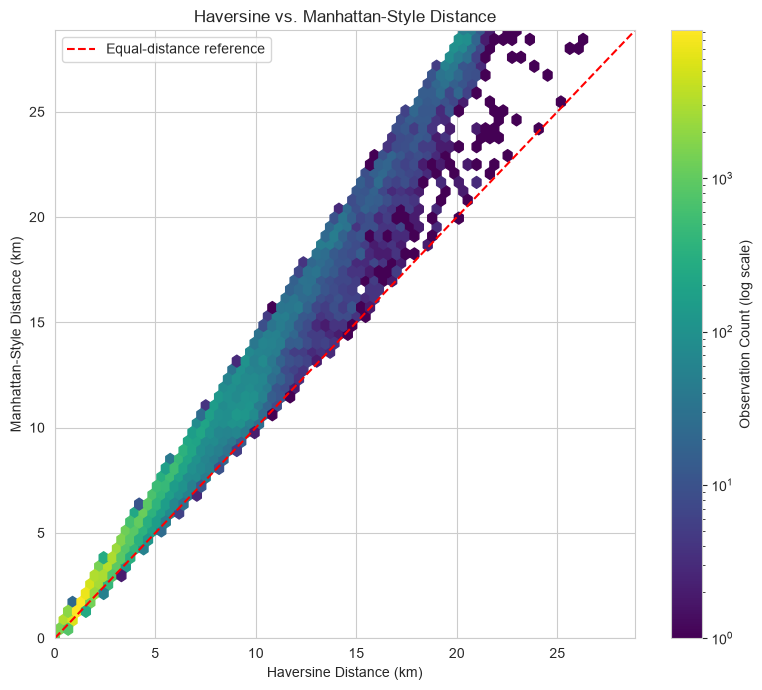

In [53]:
plot_distance_metric_comparison(df)

In [54]:
display(summarize_distance_metric_comparison(df).round(3))

,valid_trip_count,haversine_median_km,manhattan_median_km,median_difference_km,mean_difference_km,p90_difference_km,p99_difference_km,maximum_difference_km,manhattan_greater_pct,equal_distances_pct,median_ratio_positive_haversine,p90_ratio_positive_haversine,zero_haversine_count
0,1000000,2.091,2.686,0.578,1.005,2.121,8.18,368.192,99.535,0.457,1.327,1.409,4085


##### Interpretation

Manhattan-style distance is greater than Haversine distance in 99.535% of valid trips. The hexbin plot shows a dense, upward-sloping relationship, with most observations positioned above the equal-distance reference line. Exactly equal distances account for 0.457% of observations, including the 4,085 trips with identical pickup and drop-off coordinates.

The difference between the two distance estimates increases across the upper tail of the distance distribution. The median difference is 0.578 km, while the 90th-percentile difference reaches 2.121 km and the 99th-percentile difference reaches 8.18 km. The maximum difference is 368.192 km, highlighting the influence of extreme geographic observations.

The ratio of Manhattan-style distance to Haversine distance has a median of 1.327 among trips with positive Haversine distance. This indicates that the Manhattan-style estimate is typically about 32.7% greater than the Haversine estimate. However, the relationship is not an exact constant proportion, as the differences between the metrics become more pronounced for some longer trips.

Both measures capture the geographic separation between pickup and drop-off locations, but they represent it differently. Haversine distance estimates great-circle separation, whereas Manhattan-style distance adds approximate north–south and east–west components. Neither measure accounts for actual road networks, one-way streets, traffic conditions, or route restrictions.

Overall, the two distance features contain related but non-identical geometric information. The observed differences provide a reason to evaluate both features in the Ridge Regression pipeline, but these descriptive results alone cannot establish whether including both improves predictive performance. That decision must be based on controlled validation experiments.

---

#### 4. Distance Relationship Features and Trip Duration

The distance relationship features describe how Haversine and Manhattan-style distance differ from one another. `distance_ratio` represents their relative magnitude, while `distance_difference` represents their absolute difference.

This analysis compares these engineered features with the two original distance estimates to examine how trip-duration patterns change across their value ranges.

For each feature, observations are divided into approximately equal-frequency bins. The number of trips, mean duration, median duration, and 90th-percentile duration are calculated for each bin.

Comparing these patterns helps determine whether the relationship features reveal associations with trip duration that are not as apparent when examining the individual distance estimates. However, differences in the descriptive patterns do not establish that the engineered features provide additional predictive value to the Ridge Regression model.

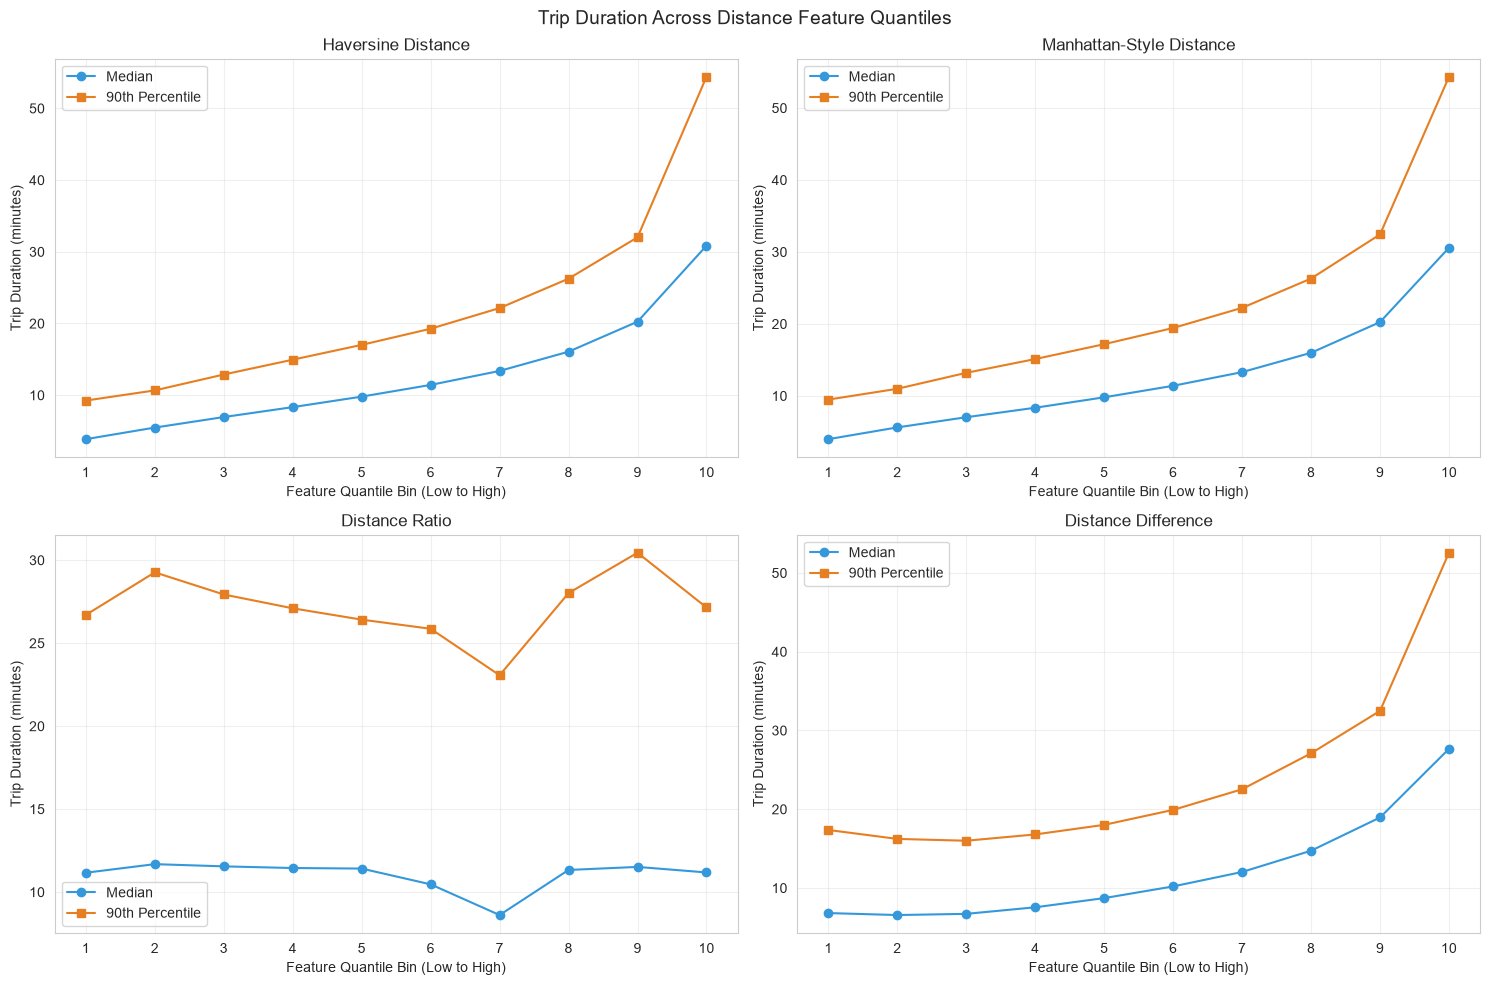

In [55]:
distance_relationship_summaries = summarize_distance_relationship_patterns(
    df,
    n_bins=10,
)

plot_distance_relationship_patterns(distance_relationship_summaries)

In [56]:
display(distance_relationship_summaries["feature_distributions"].round(3))

,valid_count,mean,median,p90,maximum,skewness
feature,,,,,,
haversine_distance,1000000,3.439,2.091,7.621,1240.909,41.885
manhattan_distance,1000000,4.444,2.686,9.668,1328.091,34.780
distance_ratio,1000000,1.281,1.327,1.409,1.414,-3.286
distance_difference,1000000,1.005,0.578,2.121,368.192,29.300


In [57]:
for feature, summary in distance_relationship_summaries["duration_by_bin"].items():
    print(f"\n{feature.replace('_', ' ').title()}")
    display(summary.round(2))


Haversine Distance


,feature_bin,trip_count,trip_share_pct,mean_duration_minutes,median_duration_minutes,p90_duration_minutes
0,"(-0.001, 0.792]",100000,10.0,6.79,3.87,9.25
1,"(0.792, 1.09]",100000,10.0,8.14,5.48,10.67
2,"(1.09, 1.38]",100000,10.0,9.64,6.95,12.88
3,"(1.38, 1.704]",100000,10.0,11.27,8.33,14.95
4,"(1.704, 2.091]",100000,10.0,12.38,9.80,17.02
5,"(2.091, 2.595]",100000,10.0,14.10,11.43,19.27
6,"(2.595, 3.331]",100000,10.0,16.73,13.38,22.15
7,"(3.331, 4.614]",100000,10.0,19.53,16.07,26.25
8,"(4.614, 7.621]",100000,10.0,23.74,20.25,32.02
9,"(7.621, 1240.909]",100000,10.0,36.85,30.85,54.40



Manhattan Distance


,feature_bin,trip_count,trip_share_pct,mean_duration_minutes,median_duration_minutes,p90_duration_minutes
0,"(-0.001, 1.0]",100000,10.0,6.92,3.98,9.48
1,"(1.0, 1.386]",100000,10.0,8.25,5.62,10.98
2,"(1.386, 1.762]",100000,10.0,9.64,7.03,13.20
3,"(1.762, 2.183]",100000,10.0,11.50,8.35,15.12
4,"(2.183, 2.686]",100000,10.0,12.25,9.80,17.18
5,"(2.686, 3.343]",100000,10.0,14.11,11.40,19.43
6,"(3.343, 4.297]",100000,10.0,16.53,13.30,22.23
7,"(4.297, 5.984]",100000,10.0,19.47,15.98,26.30
8,"(5.984, 9.668]",100000,10.0,23.85,20.25,32.43
9,"(9.668, 1328.091]",100000,10.0,36.61,30.58,54.34



Distance Ratio


,feature_bin,trip_count,trip_share_pct,mean_duration_minutes,median_duration_minutes,p90_duration_minutes
0,"(-0.001, 1.09]",100000,10.0,15.75,11.17,26.70
1,"(1.09, 1.168]",100000,10.0,16.87,11.68,29.27
2,"(1.168, 1.233]",100000,10.0,16.30,11.55,27.93
3,"(1.233, 1.286]",100000,10.0,16.25,11.45,27.10
4,"(1.286, 1.327]",100000,10.0,15.85,11.42,26.42
5,"(1.327, 1.356]",100000,10.0,15.07,10.47,25.87
6,"(1.356, 1.373]",100000,10.0,13.07,8.62,23.07
7,"(1.373, 1.395]",100000,10.0,16.28,11.33,28.02
8,"(1.395, 1.409]",100000,10.0,17.56,11.52,30.45
9,"(1.409, 1.414]",100000,10.0,16.14,11.18,27.15



Distance Difference


,feature_bin,trip_count,trip_share_pct,mean_duration_minutes,median_duration_minutes,p90_duration_minutes
0,"(-0.00100000000108, 0.123]",100000,10.0,10.42,6.82,17.37
1,"(0.123, 0.237]",100000,10.0,10.41,6.57,16.23
2,"(0.237, 0.34]",100000,10.0,10.23,6.72,16.00
3,"(0.34, 0.449]",100000,10.0,11.13,7.55,16.80
4,"(0.449, 0.578]",100000,10.0,11.97,8.72,18.02
5,"(0.578, 0.74]",100000,10.0,13.44,10.20,19.92
6,"(0.74, 0.972]",100000,10.0,15.59,12.03,22.53
7,"(0.972, 1.353]",100000,10.0,18.84,14.73,27.10
8,"(1.353, 2.121]",100000,10.0,22.99,18.95,32.48
9,"(2.121, 368.192]",100000,10.0,34.13,27.67,52.57


##### Interpretation

The analysis reveals different relationships with trip duration across the four distance-related features. Haversine distance, Manhattan-style distance, and `distance_difference` exhibit strong positive trends: as their values increase across the quantile bins, both median and 90th-percentile trip durations generally increase. In contrast, `distance_ratio` shows no clear monotonic relationship with trip duration.

The quantile summaries divide the one million valid observations into ten bins of 100,000 trips each, with each bin representing 10% of the observations. This allows duration patterns to be compared across increasing feature values without allowing the most frequent value ranges to dominate the analysis solely because of their observation counts.

For Haversine distance, the 90th-percentile duration reaches 54.40 minutes in the highest bin. The corresponding value for `distance_difference` is 52.57 minutes. Both features show a substantial increase in upper-tail duration at higher values, similar to the pattern observed for Manhattan-style distance.

The relationship between `distance_ratio` and trip duration is less consistent. Median durations fluctuate between 8.62 and 11.68 minutes across its ten bins, while the 90th-percentile durations remain comparatively stable, generally between 26 and 30 minutes. This suggests that the ratio has a weaker standalone descriptive relationship with trip duration than the raw distance features and their absolute difference.

However, these findings do not establish that `distance_ratio` is useless for prediction. A feature can have a weak standalone relationship with the target while still providing useful information alongside other features. Similarly, the strong pattern observed for `distance_difference` does not establish that it adds information beyond Haversine and Manhattan-style distance.

Overall, Haversine distance, Manhattan-style distance, and `distance_difference` display similar increasing duration patterns, while `distance_ratio` shows no clear monotonic trend. These results help characterize the engineered features, but their individual and combined predictive contributions must be assessed through controlled Ridge Regression validation experiments.

---

## EDA Conclusions and Next Steps

### Key Findings

The exploratory analysis examined the original dataset, the engineered features, and their relationships with trip duration. Several findings will guide the next stage of model development.

**Geographic distance and trip duration**

Haversine and Manhattan-style distance exhibit clear positive relationships with trip duration. Both distance distributions are strongly right-skewed, and applying `log1p` substantially reduces their skewness. The two distance estimates contain related information, while `distance_difference` follows a similar increasing relationship with duration. The descriptive relationship between `distance_ratio` and trip duration is comparatively weak.

**Temporal patterns**

Trip duration varies across pickup hours, days of the week, and the observed months. Weekday trips have higher median and 90th-percentile durations than weekend trips, while the defined rush-hour group also exhibits slightly longer durations. The cyclical time encodings correctly represent the periodic relationships between neighboring hours and days.

**Geographic concentration and airport proximity**

Pickup and drop-off locations are concentrated in a relatively small geographic region, with differences in the spatial distributions of the two endpoints. Trip-duration distributions also vary across spatial grid categories and airport-distance bands. However, proximity to an airport reference point does not confirm that a trip is an airport journey.

**Data-quality observations**

The analysis identifies 4,085 trips with identical pickup and drop-off coordinates, representing 0.409% of the training observations. It also identifies extreme geographic distances, including a maximum Haversine distance of 1,240.909 km. These records warrant investigation, but the EDA alone cannot establish their causes or determine which observations should be removed.

**Categorical features and sparsity**

Trip-duration distributions differ across vendors, store-and-forward flags, and temporal categories. Individual spatial grid categories are concentrated in a relatively small number of frequently observed cells, whereas the combined pickup–drop-off grid feature contains many rare categories. This high cardinality should be considered when configuring categorical preprocessing.

### Limitations

These findings describe the training data and help generate hypotheses about potentially useful features. They do not establish causation or demonstrate that any engineered feature improves prediction.

Several features also represent overlapping information. In particular, Haversine distance, Manhattan-style distance, their logarithmic transformations, and their derived relationship features may provide redundant information. Extreme and zero-distance observations may also affect the fitted model.

The contribution of these features, transformations, and preprocessing decisions must therefore be assessed empirically.

### Next Steps: Model Validation and Feature Evaluation

The next stage will use the existing Ridge Regression model with `alpha=1.0` to evaluate the hypotheses generated by the EDA.

The experiments will focus on:

1. **Establishing a baseline:** preserve the existing baseline results as a reference for subsequent experiments.
2. **Evaluating feature groups:** compare geographic, temporal, airport-proximity, categorical, and interaction features using controlled experiments.
3. **Testing transformations:** evaluate the contribution of the log-transformed target, log-scaled distances, and distance relationship features without assuming that they improve performance.
4. **Investigating preprocessing choices:** assess explicit criteria for potentially anomalous records and compare approaches to rare spatial categories.
5. **Comparing validation performance:** use the same validation split and evaluation metric for each experiment so that changes in performance can be compared consistently.

Only changes supported by validation results should be adopted into the final pipeline. The test set will remain untouched until the final evaluation.
